# Capstone Project — Clustering Track
## 23CSE301 Machine Learning · B.Tech. CSE (III Year) · Academic Year 2026-27 · Review 2

**Dataset:** Dry Bean Dataset (Koklu & Ozkan, 2020) — 13,611 dry beans, 16 geometric/shape features extracted from images, 7 registered varieties.
**Track:** Clustering — K-Means and Agglomerative Hierarchical Clustering.
**Team:** *<Member 1 – CB.SC.U4CSE24712>, <Member 2 – CB.SC.U4CSE24761>, <Member 3 – CB.SC.U4CSE24727>*

---

### Problem statement
Dry beans are graded into seven varieties (Barbunya, Bombay, Cali, Dermason, Horoz, Seker, Sira). Grading normally needs a human expert or a labelled image classifier. Here we ask a purely **unsupervised** question:

> *Using only the 16 geometric features extracted from bean images — with no access to the variety labels during training — can K-Means and Agglomerative Hierarchical Clustering discover groups that correspond to meaningful bean varieties, and which algorithm / configuration recovers this structure best?*

The `Class` column is **never** used while fitting or tuning a model. It is used only *afterwards*, to interpret and validate the discovered clusters, exactly as the course guidelines require.

### Guideline coverage map

| Guideline requirement | Where in this notebook |
|---|---|
| Dataset loading, audit (A1) | Section 2 |
| EDA — distributions, outliers, correlation, scatter plots + written insight commentary (A2, A3) | Section 3 |
| Cleaning, scaling (justified), feature-space variants (B1, B2) | Section 4 |
| K-Means implementation + mandatory **Elbow curve** (inertia vs k) | Section 6 |
| Agglomerative implementation + mandatory **Dendrogram**, linkage comparison | Section 7 |
| **Hyperparameter tuning** for both algorithms | Section 8 |
| Silhouette, Davies-Bouldin, Calinski-Harabasz reported for **every** algorithm/variant | Sections 5, 9 |
| **PCA (2 components) plot for every algorithm** (mandatory) + **t-SNE** (encouraged) | Section 10 |
| Cluster interpretation, profiling, post-hoc validation against true varieties | Section 11 |
| Robustness / generalisation checks (train-only scaler fit, seed stability) | Section 12 |
| Final model selection, conclusions | Section 13 |
| Saved artefacts for a bonus GUI (`models/kmeans_final_pipeline.pkl`) | Section 14 |

### How to run
1. Place `Dry_Bean_Dataset.xlsx` in `data/` (repo layout: `notebooks/`, `data/`, `models/`).
2. `pip install -r requirements.txt` (numpy, pandas, scipy, scikit-learn, matplotlib, seaborn, joblib, openpyxl).
3. **Kernel → Restart & Run All** (about 5-10 minutes on a laptop; the K-Means tuning grid and t-SNE dominate the run time).

## 1. Setup
`random_state = 42` is used everywhere so results are reproducible (guideline §7.1). The Seaborn **colorblind** palette is used throughout (guideline §7.3).

In [1]:
import os, time, itertools, warnings
from pathlib import Path
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib, json

from scipy.cluster.hierarchy import linkage, dendrogram, fcluster, cophenet
from scipy.spatial.distance import pdist
from scipy.stats import spearmanr

from sklearn.preprocessing import StandardScaler, RobustScaler, MinMaxScaler
from sklearn.compose import ColumnTransformer
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.neighbors import NearestNeighbors
from sklearn.pipeline import Pipeline
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.model_selection import train_test_split
from sklearn.metrics import (silhouette_score, silhouette_samples, davies_bouldin_score,
                             calinski_harabasz_score, adjusted_rand_score,
                             normalized_mutual_info_score, homogeneity_completeness_v_measure,
                             pairwise_distances_argmin)

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

sns.set_theme(style="whitegrid", palette="colorblind", context="notebook")
PAL = sns.color_palette("colorblind", 10)
plt.rcParams.update({"figure.dpi": 100, "axes.titlesize": 12, "axes.titleweight": "bold",
                     "axes.labelsize": 10, "legend.fontsize": 8})
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 40)

# Expected repo layout: notebooks/ (this file), data/, models/. Falls back gracefully if run elsewhere.
DATA_CANDIDATES = ["../data/Dry_Bean_Dataset.xlsx", "data/Dry_Bean_Dataset.xlsx",
                   "Dry_Bean_Dataset.xlsx", "/mnt/user-data/uploads/Dry_Bean_Dataset.xlsx"]
DATA_PATH = next(p for p in DATA_CANDIDATES if os.path.exists(p))
MODELS_DIR = Path("../models") if Path("../data").exists() else Path("models")
MODELS_DIR.mkdir(parents=True, exist_ok=True)
print("Data file :", DATA_PATH)
print("Models dir:", MODELS_DIR)

Data file : Dry_Bean_Dataset.xlsx
Models dir: models


## 2. Dataset Loading & Audit
We report shape, dtypes, missing values, duplicates, and the (held-out) class distribution, per guideline **A1**. Two column names are tidied (`AspectRation → AspectRatio`, `roundness → Roundness`) — purely cosmetic.

In [2]:
raw = pd.read_excel(DATA_PATH, sheet_name="Dry_Beans_Dataset")
raw = raw.rename(columns={"AspectRation": "AspectRatio", "roundness": "Roundness"})

print(f"Shape                : {raw.shape[0]:,} rows x {raw.shape[1]} columns")
print(f"Total missing values : {int(raw.isna().sum().sum())}")
print(f"Duplicate rows       : {int(raw.duplicated().sum())}")
print("\nData types:")
display(raw.dtypes.rename("dtype").to_frame().T)
print("\nFirst five rows:")
display(raw.head())
print("\nDescriptive statistics:")
display(raw.describe().T.round(3))

Shape                : 13,611 rows x 17 columns
Total missing values : 0
Duplicate rows       : 68

Data types:


,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRatio,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,Roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4,Class
dtype,int64,float64,float64,float64,float64,float64,int64,float64,float64,float64,float64,float64,float64,float64,float64,float64,str



First five rows:


,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRatio,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,Roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4,Class
0,28395,610.291,208.178117,173.888747,1.197191,0.549812,28715,190.141097,0.763923,0.988856,0.958027,0.913358,0.007332,0.003147,0.834222,0.998724,SEKER
1,28734,638.018,200.524796,182.734419,1.097356,0.411785,29172,191.272750,0.783968,0.984986,0.887034,0.953861,0.006979,0.003564,0.909851,0.998430,SEKER
2,29380,624.110,212.826130,175.931143,1.209713,0.562727,29690,193.410904,0.778113,0.989559,0.947849,0.908774,0.007244,0.003048,0.825871,0.999066,SEKER
3,30008,645.884,210.557999,182.516516,1.153638,0.498616,30724,195.467062,0.782681,0.976696,0.903936,0.928329,0.007017,0.003215,0.861794,0.994199,SEKER
4,30140,620.134,201.847882,190.279279,1.060798,0.333680,30417,195.896503,0.773098,0.990893,0.984877,0.970516,0.006697,0.003665,0.941900,0.999166,SEKER



Descriptive statistics:


,count,mean,std,min,25%,50%,75%,max
Area,13611.0,53048.285,29324.096,20420.000,36328.000,44652.000,61332.000,254616.000
Perimeter,13611.0,855.283,214.290,524.736,703.523,794.941,977.213,1985.370
MajorAxisLength,13611.0,320.142,85.694,183.601,253.304,296.883,376.495,738.860
MinorAxisLength,13611.0,202.271,44.970,122.513,175.848,192.432,217.032,460.198
AspectRatio,13611.0,1.583,0.247,1.025,1.432,1.551,1.707,2.430
Eccentricity,13611.0,0.751,0.092,0.219,0.716,0.764,0.810,0.911
ConvexArea,13611.0,53768.200,29774.916,20684.000,36714.500,45178.000,62294.000,263261.000
EquivDiameter,13611.0,253.064,59.177,161.244,215.068,238.438,279.446,569.374
Extent,13611.0,0.750,0.049,0.555,0.719,0.760,0.787,0.866
Solidity,13611.0,0.987,0.005,0.919,0.986,0.988,0.990,0.995


,count,share_%
Class,,
DERMASON,3546,26.05
SIRA,2636,19.37
SEKER,2027,14.89
HOROZ,1928,14.17
CALI,1630,11.98
BARBUNYA,1322,9.71
BOMBAY,522,3.84


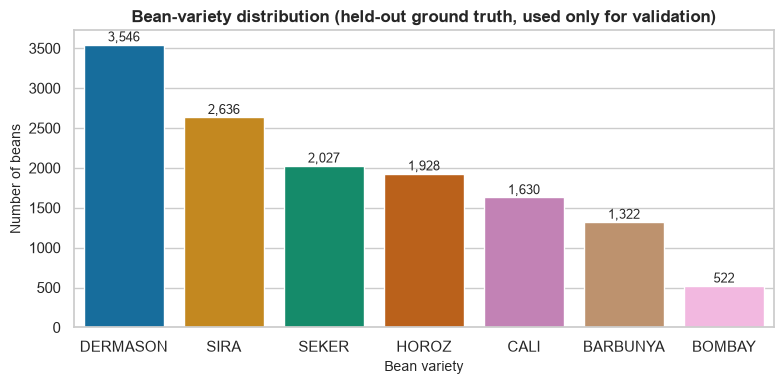

In [3]:
class_counts = raw["Class"].value_counts()
class_share = (class_counts / len(raw) * 100).round(2)
display(pd.DataFrame({"count": class_counts, "share_%": class_share}))

fig, ax = plt.subplots(figsize=(8, 4))
sns.barplot(x=class_counts.index, y=class_counts.values, hue=class_counts.index, palette="colorblind", legend=False, ax=ax)
for i, v in enumerate(class_counts.values):
    ax.text(i, v + 40, f"{v:,}", ha="center", fontsize=9)
ax.set_title("Bean-variety distribution (held-out ground truth, used only for validation)")
ax.set_xlabel("Bean variety"); ax.set_ylabel("Number of beans")
plt.tight_layout(); plt.show()

**Observation.** The dataset has 13,611 beans, 16 numeric shape features, and no missing values, so no imputation is required. 68 exact duplicate rows are present (all belonging to the Horoz variety); they are removed in Section 4. The seven varieties are **imbalanced**: Dermason (~26%) and Sira (~19%) dominate, while Bombay is by far the rarest at only 522 beans (~3.8% of the data). This matters for clustering because a naive algorithm can easily merge Bombay into a neighbouring cluster or, conversely, an algorithm that isolates a handful of extreme points can masquerade as "finding" Bombay — both failure modes are guarded against by the cluster-size validity filter defined in Section 5.

## 3. Exploratory Data Analysis (EDA)
### 3.1 Feature distributions

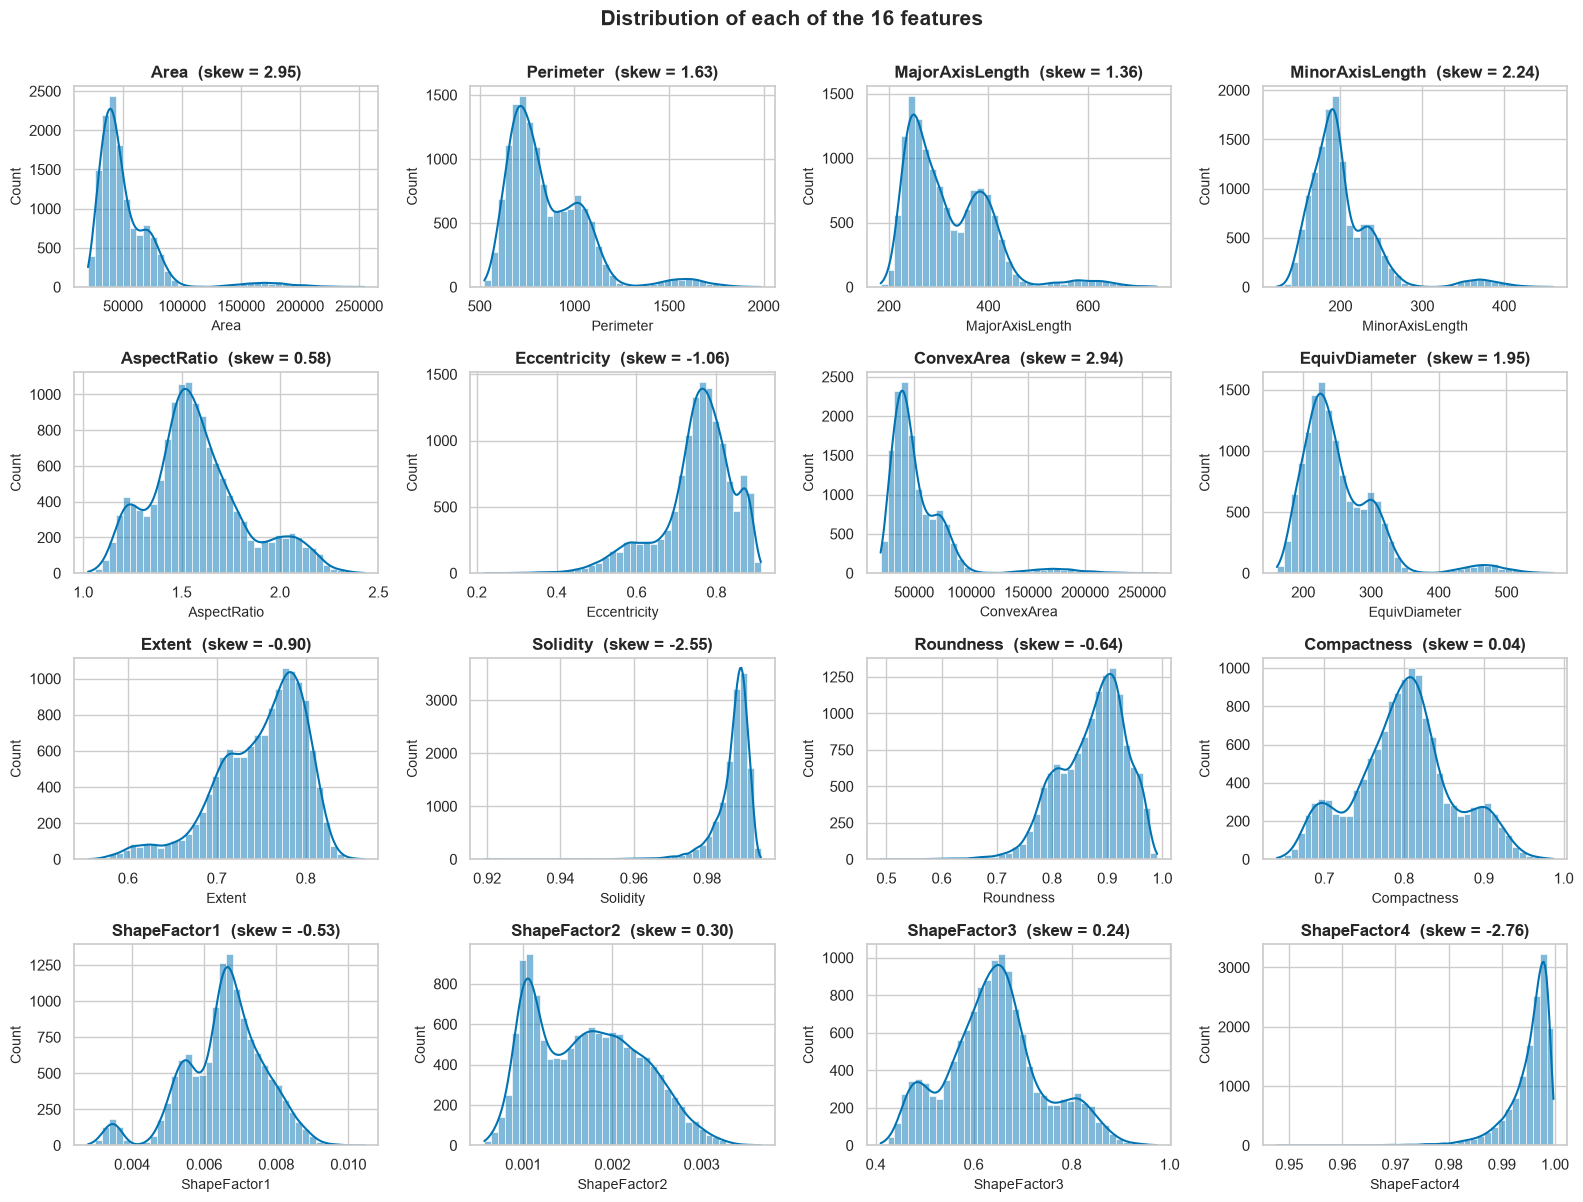

Most right-skewed features : {'Area': 2.95, 'ConvexArea': 2.94, 'MinorAxisLength': 2.24, 'EquivDiameter': 1.95}
Most left-skewed features  : {'Extent': -0.9, 'Eccentricity': -1.06, 'Solidity': -2.55, 'ShapeFactor4': -2.76}


In [4]:
feature_cols = [c for c in raw.columns if c != "Class"]
fig, axes = plt.subplots(4, 4, figsize=(16, 12))
for ax, col in zip(axes.ravel(), feature_cols):
    sns.histplot(raw[col], kde=True, bins=40, color=PAL[0], ax=ax)
    ax.set_title(f"{col}  (skew = {raw[col].skew():.2f})")
    ax.set_xlabel(col); ax.set_ylabel("Count")
fig.suptitle("Distribution of each of the 16 features", fontsize=15, fontweight="bold", y=1.0)
plt.tight_layout(); plt.show()

skew_tbl = raw[feature_cols].skew().sort_values(ascending=False).round(2)
print("Most right-skewed features :", skew_tbl.head(4).to_dict())
print("Most left-skewed features  :", skew_tbl.tail(4).to_dict())

**Observation.** The size-related features (`Area`, `Perimeter`, `ConvexArea`, `EquivDiameter`, `MajorAxisLength`) are right-skewed with a long upper tail — this tail is largely the large-bodied Bombay variety sitting apart from the other six. Shape-descriptor features that are ratios (`Eccentricity`, `Solidity`, `Extent`, `Roundness`, `Compactness`, `ShapeFactor1-4`) are on very different scales from the size features and several (e.g. `Solidity`, `Extent`) are strongly left-skewed with tight concentration near 1, which limits how much separating power they contribute on their own. The wildly different scales (`Area` in the tens of thousands versus `Solidity` near 1) also make scaling non-optional for distance-based clustering.

### 3.2 Outlier view (IQR rule) and box-plots

feature,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRatio,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,Roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4
n_outliers,551.00,500.00,379.00,569.00,473.00,843.00,550.00,526.00,275.00,778.00,91.00,109.0,533.00,0.0,195.00,767.00
outlier_%,4.05,3.67,2.78,4.18,3.48,6.19,4.04,3.86,2.02,5.72,0.67,0.8,3.92,0.0,1.43,5.64


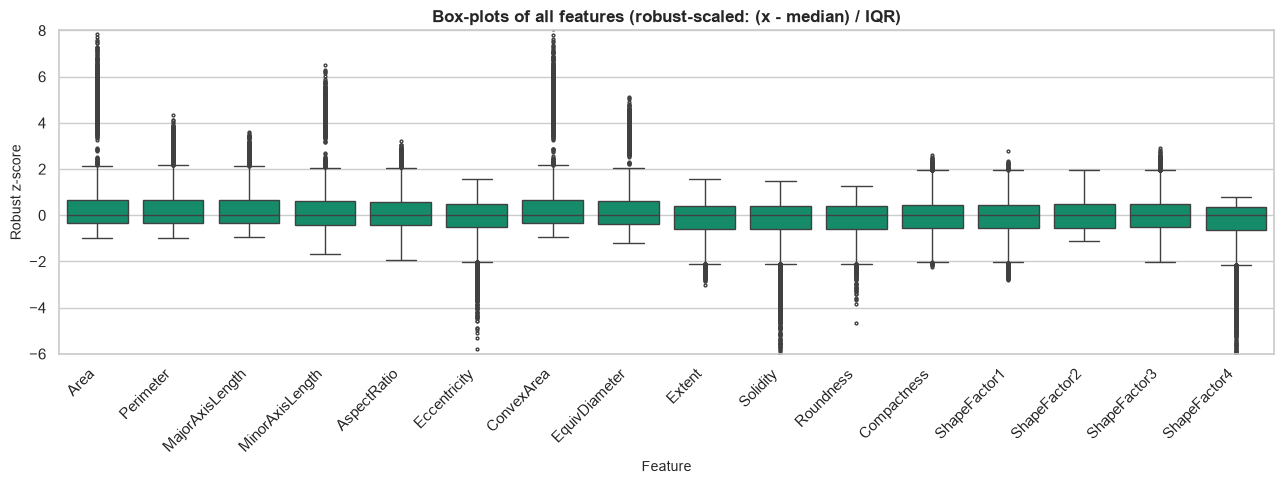

In [5]:
def iqr_outlier_table(df, cols):
    rows = []
    for c in cols:
        q1, q3 = df[c].quantile([.25, .75]); iqr = q3 - q1
        lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
        n_out = int(((df[c] < lo) | (df[c] > hi)).sum())
        rows.append((c, n_out, round(100 * n_out / len(df), 2)))
    return pd.DataFrame(rows, columns=["feature", "n_outliers", "outlier_%"]).set_index("feature")

out_tbl = iqr_outlier_table(raw, feature_cols)
display(out_tbl.T)

Zbox = (raw[feature_cols] - raw[feature_cols].median()) / (raw[feature_cols].quantile(.75) - raw[feature_cols].quantile(.25))
fig, ax = plt.subplots(figsize=(13, 5))
sns.boxplot(data=Zbox, orient="v", color=PAL[2], fliersize=2, ax=ax)
ax.set_title("Box-plots of all features (robust-scaled: (x - median) / IQR)")
ax.set_xlabel("Feature"); ax.set_ylabel("Robust z-score"); ax.set_ylim(-6, 8)
plt.xticks(rotation=45, ha="right"); plt.tight_layout(); plt.show()

**Observation.** IQR-flagged outliers appear in essentially every feature, and are most numerous in the size-related features and in some shape ratios (e.g. `Solidity`, `Extent`, `Compactness`). Inspecting them shows they are real, physically plausible beans (the large-bodied Bombay beans, and beans with irregular outlines or imperfect image segmentation), not sensor or data-entry errors. We therefore retain all rows and manage their influence on distance-based clustering through the choice of **scaler** (Standard vs Robust vs Min-Max) that is tuned in Section 8, rather than deleting data — deleting them would remove exactly the Bombay cluster we hope to discover.

### 3.3 Correlation heat-map

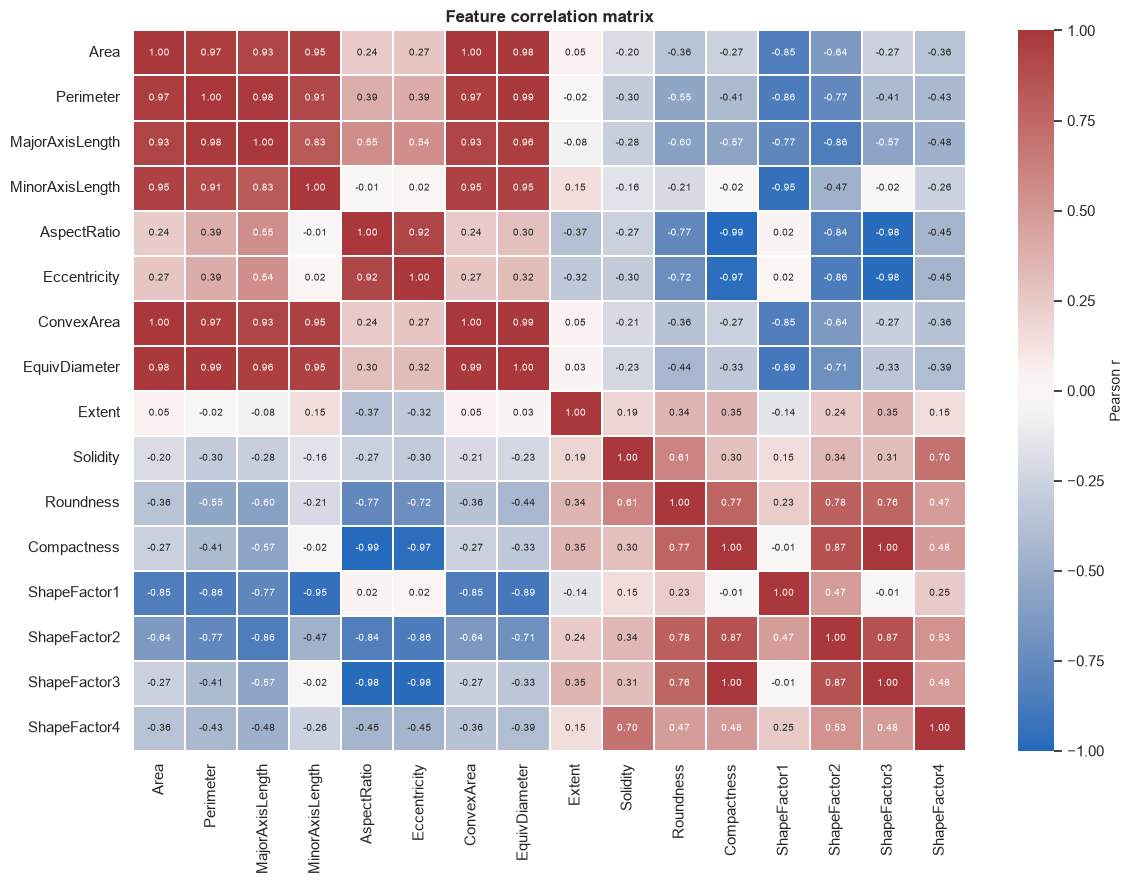

Most correlated feature pairs:


,,|r|
Area,ConvexArea,0.9999
Compactness,ShapeFactor3,0.9987
Perimeter,EquivDiameter,0.9914
AspectRatio,Compactness,0.9877
ConvexArea,EquivDiameter,0.9852
Area,EquivDiameter,0.9850
Eccentricity,ShapeFactor3,0.9811
AspectRatio,ShapeFactor3,0.9786


In [6]:
corr = raw[feature_cols].corr()
fig, ax = plt.subplots(figsize=(12, 9))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="vlag", center=0, vmin=-1, vmax=1,
            annot_kws={"size": 7}, linewidths=.3, cbar_kws={"label": "Pearson r"}, ax=ax)
ax.set_title("Feature correlation matrix")
plt.tight_layout(); plt.show()

upper = corr.abs().where(np.triu(np.ones(corr.shape), 1).astype(bool))
top_pairs = upper.stack().sort_values(ascending=False).head(8).round(4)
print("Most correlated feature pairs:"); display(top_pairs.rename("|r|").to_frame())

**Observation.** `Area`, `Perimeter`, `ConvexArea`, `EquivDiameter` and `MajorAxisLength` are almost perfectly correlated (|r| close to 1) — unsurprising, since they are five different mathematical ways of measuring the same underlying "how big is this bean" quantity. `Compactness`, `ShapeFactor1`, `AspectRatio`, `Eccentricity` and `ShapeFactor3` also correlate strongly with each other, as they all encode elongation/circularity. This redundancy means K-Means (which uses Euclidean distance) would otherwise let "size" and "elongation" dominate the distance calculation several times over; the `decorr` feature-space variant built in Section 4.3 corrects for this.

### 3.4 Feature–feature scatter plots and pair-plot
Colours below show the true variety **for interpretation only** — no clustering algorithm sees this column.

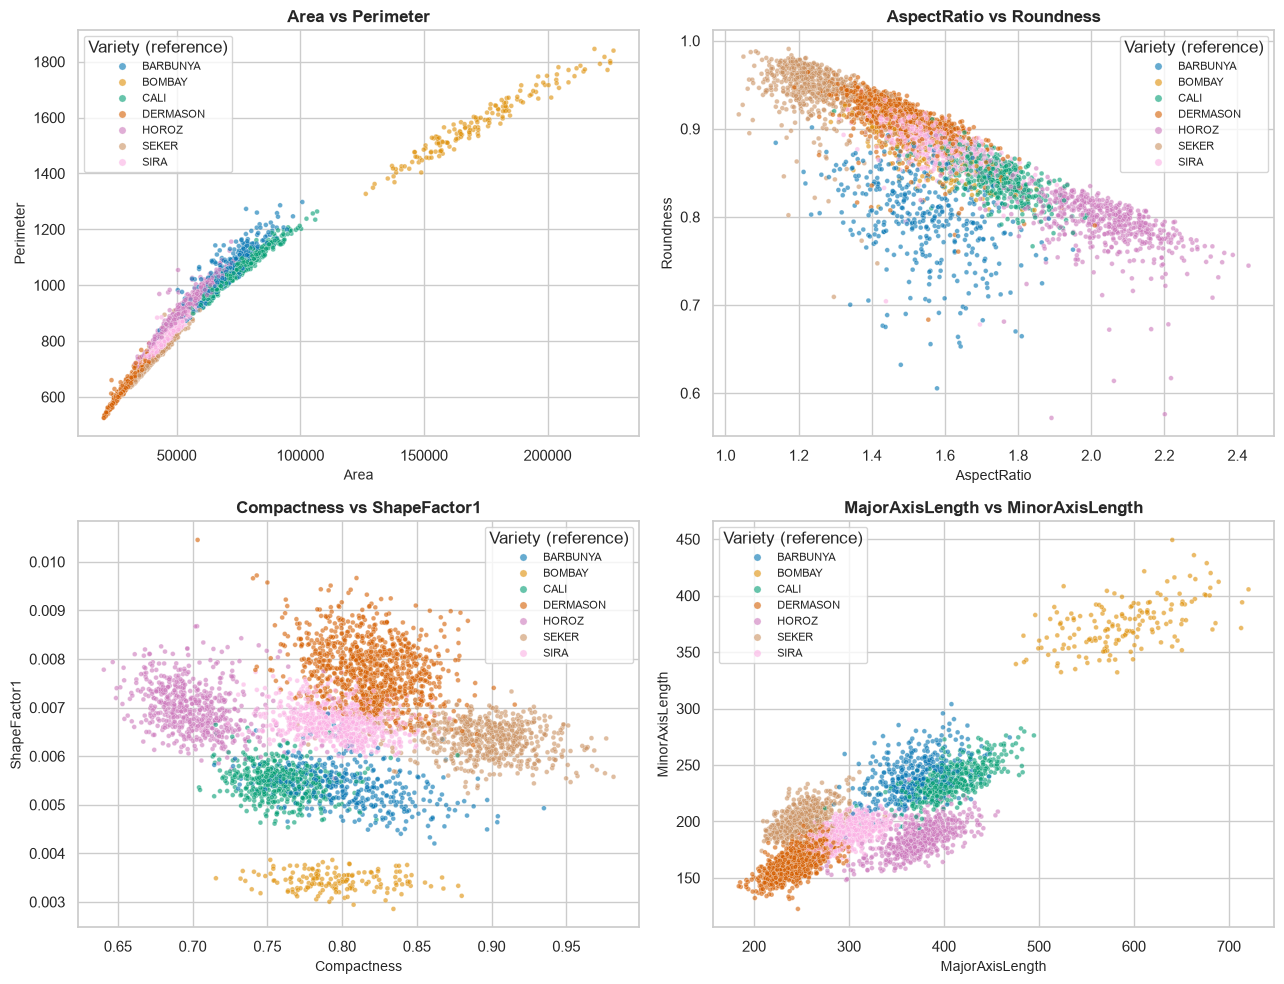

In [7]:
pairs = [("Area", "Perimeter"), ("AspectRatio", "Roundness"), ("Compactness", "ShapeFactor1"), ("MajorAxisLength", "MinorAxisLength")]
fig, axes = plt.subplots(2, 2, figsize=(13, 10))
order = sorted(raw["Class"].unique())
for ax, (a, b) in zip(axes.ravel(), pairs):
    sns.scatterplot(data=raw.sample(4000, random_state=RANDOM_STATE), x=a, y=b, hue="Class", hue_order=order,
                    palette="colorblind", s=12, alpha=.6, ax=ax)
    ax.set_title(f"{a} vs {b}"); ax.legend(title="Variety (reference)", loc="best", markerscale=1.5)
plt.tight_layout(); plt.show()

**Observation.** `Area` vs `Perimeter` shows Bombay clearly separated in the upper-right corner, with the remaining six varieties forming a dense, overlapping band — consistent with Bombay being trivial to isolate but the other varieties requiring finer shape cues. `AspectRatio` vs `Roundness` shows the expected inverse relationship: elongated varieties (Horoz, Sira) sit at high aspect ratio / low roundness, while round varieties (Seker, Bombay) sit at the opposite end. This is encouraging: the *shape* features, not just size, carry real discriminating signal for clustering.

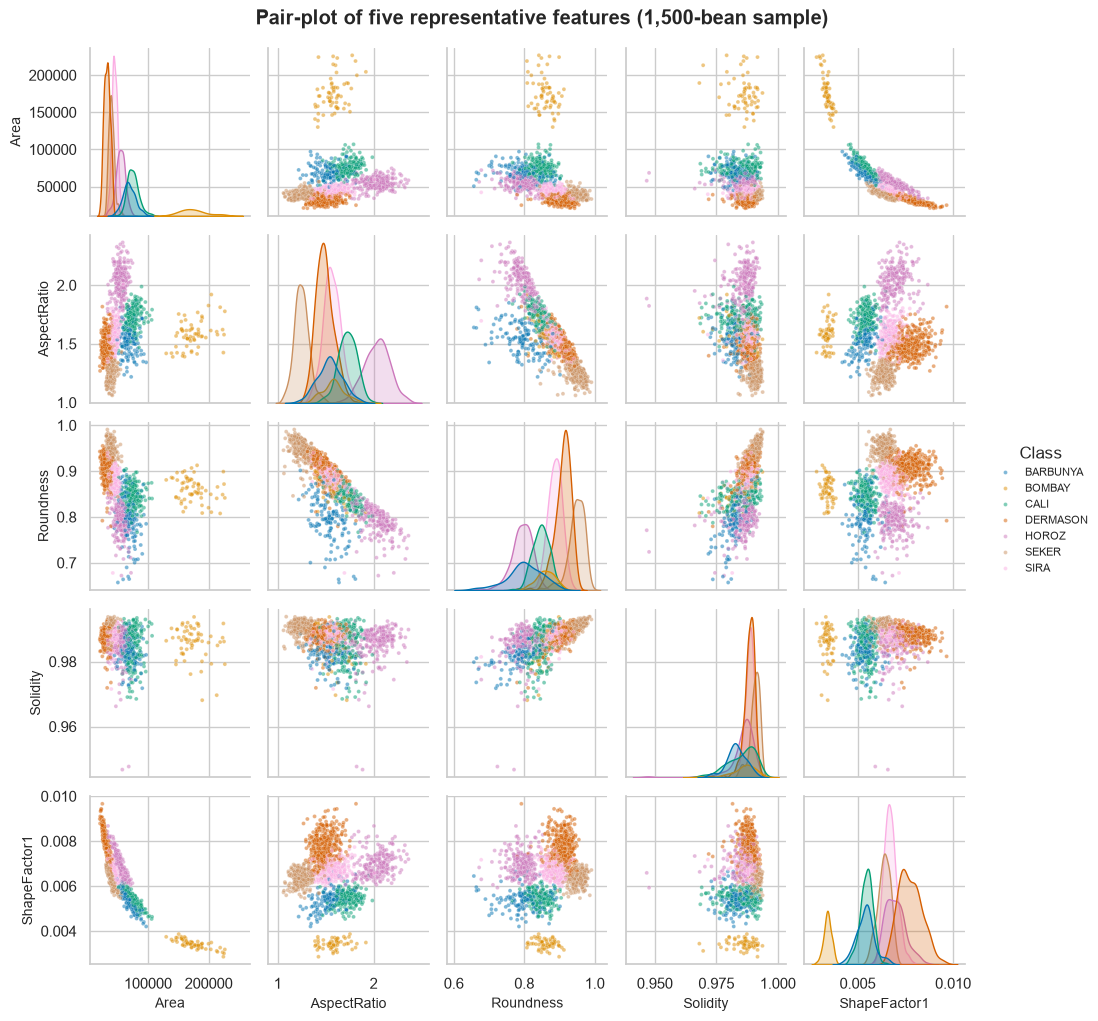

In [8]:
sel = ["Area", "AspectRatio", "Roundness", "Solidity", "ShapeFactor1"]
g = sns.pairplot(raw.sample(1500, random_state=RANDOM_STATE), vars=sel, hue="Class", hue_order=order,
                 palette="colorblind", plot_kws={"s": 8, "alpha": .5}, diag_kind="kde", height=2.0)
g.figure.suptitle("Pair-plot of five representative features (1,500-bean sample)", y=1.02, fontweight="bold")
plt.show()

**Observation.** The diagonal KDEs confirm Bombay is unimodal and well-separated on `Area`, while the other six varieties overlap heavily in most 2-D projections and are only partially separable pairwise — meaning a clustering algorithm will likely need the *full* multi-dimensional feature space (or a PCA summary of it) rather than any single 2-feature pair to recover all seven groups.

## 4. Preprocessing & Feature-Space Design
### 4.1 Cleaning — duplicates, missing values, outliers
**Strategy and justification** (guideline **B1**)

* **Duplicates** — exact duplicate rows add no information and would give some points double weight in a distance-based algorithm, so they are dropped.
* **Missing values** — none are present (confirmed in Section 2). The code still contains a defensive median-imputation step so the pipeline is safe if the source file is refreshed.
* **Outliers** — flagged with the IQR rule in Section 3.2 but **retained**: they are real, physically plausible beans (e.g. the large-bodied *Bombay* variety), not measurement errors. Their effect on K-Means is managed instead by comparing scalers during tuning.
* **Labels** — separated into `y_true` and used **only** for post-hoc validation, never for fitting or tuning.

In [9]:
df = raw.drop_duplicates().reset_index(drop=True)
print(f"Removed {len(raw) - len(df)} duplicate rows -> {len(df):,} rows remain")

if df[feature_cols].isna().any().any():                      # defensive; not triggered for this dataset
    df[feature_cols] = df[feature_cols].fillna(df[feature_cols].median())
assert df[feature_cols].isna().sum().sum() == 0

X = df[feature_cols].copy()          # unlabeled feature matrix: the ONLY thing models see
y_true = df["Class"].copy()          # held-out labels: used only for post-hoc validation
N = len(X)
print("X shape:", X.shape, "| y_true classes:", y_true.nunique())

Removed 68 duplicate rows -> 13,543 rows remain
X shape: (13543, 16) | y_true classes: 7


### 4.2 Scaling and the reference feature space

Features live on very different scales (`Area` ~ 10⁴–10⁵, `Solidity` ~ 1), and both clustering algorithms use distance-based calculations, so scaling is required.

For the primary unsupervised analysis, the complete unlabeled feature dataset is standardized to create a common reference space. This allows the clustering structure of the available dataset to be examined without introducing a supervised target into model fitting.

The `Class` column is never used to fit or tune the clustering algorithms.

To additionally verify that the preprocessing and selected K-Means configuration remain valid when applied to unseen observations, Section 12.2 performs a separate leakage-safe 80/20 hold-out experiment. In that experiment, the scaler is fitted only on the training data and the held-out test data is transformed using that fitted scaler.

Therefore:

- **Primary clustering analysis:** complete unlabeled dataset.
- **Robustness/generalisation check:** train-only scaler fitting followed by evaluation on an untouched 20% test split.
- **Post-hoc validation:** `Class` is used only after clustering through ARI, NMI, purity and related measures.

All primary clustering-quality metrics are computed in one common reference space so that candidate configurations can be compared consistently.

In [10]:
REF = StandardScaler().fit_transform(X)          # reference space used for ALL metric comparisons
REF_DF = pd.DataFrame(REF, columns=feature_cols)
print("Reference matrix:", REF.shape, "| mean ~", REF.mean().round(6), "| std ~", REF.std().round(3))

def hopkins(Z, m=600, seed=RANDOM_STATE):
    # Hopkins statistic: ~0.5 = uniformly random data, -> 1.0 = strongly clustered
    rng = np.random.RandomState(seed); n, d = Z.shape
    nn = NearestNeighbors(n_neighbors=2).fit(Z)
    real = Z[rng.choice(n, m, replace=False)]
    w = nn.kneighbors(real, n_neighbors=2)[0][:, 1]                      # real point -> nearest OTHER real point
    U = rng.uniform(Z.min(0), Z.max(0), (m, d))
    u = nn.kneighbors(U, n_neighbors=1)[0][:, 0]                         # random point -> nearest real point
    return u.sum() / (u.sum() + w.sum())

H = np.mean([hopkins(REF, seed=s) for s in range(5)])
print(f"Hopkins statistic (mean of 5 runs): {H:.3f}  ->  " +
      ("strong cluster tendency" if H > 0.75 else "moderate cluster tendency" if H > 0.6 else "weak / no cluster tendency"))

Reference matrix: (13543, 16) | mean ~ 0.0 | std ~ 1.0
Hopkins statistic (mean of 5 runs): 0.953  ->  strong cluster tendency


**Observation.** A Hopkins statistic well above 0.5 (printed above; 0.5 = uniform random data, 1.0 = perfectly clustered) indicates genuine cluster tendency in the data rather than a uniform blob — i.e. clustering this dataset is a meaningful exercise and not something being forced onto random noise.

### 4.3 Feature-space variants (feature selection / extraction)
Several features are near-duplicates of each other (Section 3.3). We prepare three feature spaces and let the tuning stage in Section 8 decide which works best:

| Variant | Description |
|---|---|
| `all` | all 16 original features |
| `decorr` | drop one feature from every pair with \|r\| > 0.95 (removes redundancy so "size" is not effectively counted five times) |
| `pca95` | standardise, then PCA keeping 95% of the variance |

Dropped as redundant (|r| > 0.95): ['Perimeter', 'MajorAxisLength', 'MinorAxisLength', 'ConvexArea', 'EquivDiameter', 'Compactness', 'ShapeFactor3']
Decorrelated set (9 features): ['Area', 'AspectRatio', 'Eccentricity', 'Extent', 'Solidity', 'Roundness', 'ShapeFactor1', 'ShapeFactor2', 'ShapeFactor4']

PCA: 4 components explain 95.0% of variance; first 2 explain 81.9%


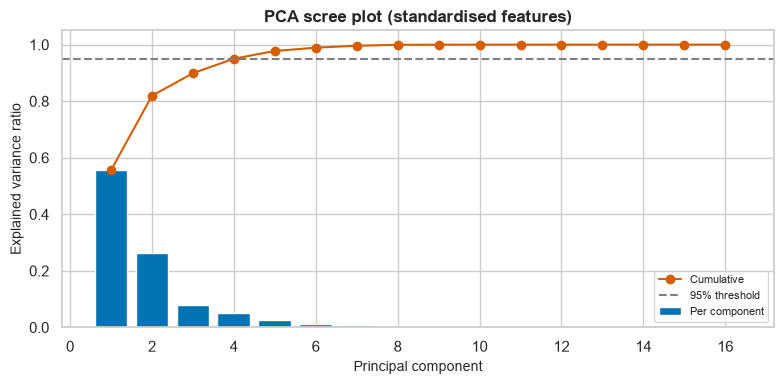

In [11]:
corr_abs = X.corr().abs()
upper = corr_abs.where(np.triu(np.ones(corr_abs.shape), 1).astype(bool))
DROP_REDUNDANT = [c for c in upper.columns if (upper[c] > 0.95).any()]
DECORR_COLS = [c for c in feature_cols if c not in DROP_REDUNDANT]
print("Dropped as redundant (|r| > 0.95):", DROP_REDUNDANT)
print(f"Decorrelated set ({len(DECORR_COLS)} features):", DECORR_COLS)

pca_full = PCA(random_state=RANDOM_STATE).fit(REF)
cum = np.cumsum(pca_full.explained_variance_ratio_)
n95 = int(np.searchsorted(cum, 0.95) + 1)
print(f"\nPCA: {n95} components explain {cum[n95-1]*100:.1f}% of variance; first 2 explain {cum[1]*100:.1f}%")

fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(range(1, 17), pca_full.explained_variance_ratio_, color=PAL[0], label="Per component")
ax.plot(range(1, 17), cum, "o-", color=PAL[3], label="Cumulative")
ax.axhline(.95, ls="--", color="gray", label="95% threshold")
ax.set_title("PCA scree plot (standardised features)"); ax.set_xlabel("Principal component"); ax.set_ylabel("Explained variance ratio")
ax.legend(); plt.tight_layout(); plt.show()

**Observation.** Because several features are near-duplicate measures of size and elongation, the first two principal components already absorb a large share of the total variance and only a handful of components are needed to reach the 95% threshold (exact numbers printed above). This confirms the feature set is highly redundant and justifies testing the `decorr` and `pca95` variants alongside the full 16-feature space during tuning.

In [12]:
SCALERS = {"standard": StandardScaler, "robust": RobustScaler, "minmax": MinMaxScaler}
FSETS = ["all", "decorr", "pca95"]

def build_features(scaler_name, fset, data=X):
    # Returns the model-input matrix for a (scaler, feature-set) combination.
    cols = feature_cols if fset in ("all", "pca95") else DECORR_COLS
    Z = SCALERS[scaler_name]().fit_transform(data[cols])
    if fset == "pca95":
        Z = PCA(n_components=0.95, random_state=RANDOM_STATE).fit_transform(Z)
    return Z

FEATS = {(s, f): build_features(s, f) for s in SCALERS for f in FSETS}
print(pd.Series({f"{s}/{f}": v.shape[1] for (s, f), v in FEATS.items()}, name="n_features").to_frame().T)

            standard/all  standard/decorr  standard/pca95  robust/all  robust/decorr  robust/pca95  minmax/all  minmax/decorr  minmax/pca95
n_features            16                9               4          16              9             4          16              9             4


## 5. Evaluation Toolkit
**Internal metrics** (mandatory; require no labels; computed in the common reference space):

| Metric | Range | Better | Idea |
|---|---|---|---|
| Silhouette Score | -1 ... 1 | higher | how much closer a point is to its own cluster than to the nearest other cluster |
| Davies-Bouldin Index | 0 ... infinity | lower | average similarity between each cluster and its most similar one (scatter / separation) |
| Calinski-Harabasz Index | 0 ... infinity | higher | ratio of between-cluster to within-cluster dispersion |

**External metrics** (post-hoc only, using the held-out varieties): Adjusted Rand Index (ARI), Normalised Mutual Information (NMI), Homogeneity / Completeness / V-measure, and Purity.

**Validity filter.** Internal metrics can be "gamed" by degenerate solutions — e.g. single/average linkage often isolates 1-3 outlier beans in their own cluster, which inflates the silhouette artificially. During tuning, any configuration with a cluster holding **< 2% of the beans** is rejected. (The rarest real variety, *Bombay*, is ~3.8% of the data, so genuine solutions comfortably pass this filter.)

In [13]:
MIN_SHARE = 0.02      # validity filter used during tuning

def internal_metrics(Z, labels, sil_sample=None):
    return {"silhouette": silhouette_score(Z, labels, sample_size=sil_sample, random_state=RANDOM_STATE) if sil_sample else silhouette_score(Z, labels),
            "davies_bouldin": davies_bouldin_score(Z, labels),
            "calinski_harabasz": calinski_harabasz_score(Z, labels)}

def purity_score(y, labels):
    ct = pd.crosstab(labels, y)
    return ct.max(axis=1).sum() / ct.values.sum()

def external_metrics(y, labels):
    h, c, v = homogeneity_completeness_v_measure(y, labels)
    return {"ARI": adjusted_rand_score(y, labels), "NMI": normalized_mutual_info_score(y, labels),
            "homogeneity": h, "completeness": c, "v_measure": v, "purity": purity_score(y, labels)}

def min_cluster_share(labels):
    return np.bincount(labels).min() / len(labels)

def full_report(Z, labels, y=y_true, sil_sample=None):
    labels = np.asarray(labels)
    return {**internal_metrics(Z, labels, sil_sample), **external_metrics(y, labels),
            "n_clusters": len(np.unique(labels)), "min_share": min_cluster_share(labels)}

def composite_rank(grid, min_share=MIN_SHARE):
    # Rank valid configs on Silhouette (high), Davies-Bouldin (low), Calinski-Harabasz (high); lower mean rank = better.
    g = grid[grid["min_share"] >= min_share].copy()
    g["rank_sil"] = g["silhouette"].rank(ascending=False)
    g["rank_db"]  = g["davies_bouldin"].rank(ascending=True)
    g["rank_ch"]  = g["calinski_harabasz"].rank(ascending=False)
    g["mean_rank"] = g[["rank_sil", "rank_db", "rank_ch"]].mean(axis=1)
    return g.sort_values(["mean_rank", "silhouette"], ascending=[True, False]).reset_index(drop=True)

def relabel(lbl):
    # sklearn/scipy labels -> consecutive ints starting at 0
    return pd.factorize(np.asarray(lbl))[0]
print("Evaluation helpers ready.")

Evaluation helpers ready.


## 6. Algorithm 1 — K-Means Clustering
K-Means alternates between (a) assigning each bean to its nearest centroid and (b) moving each centroid to the mean of its beans, minimising **inertia** (within-cluster sum of squared distances). It needs `k` chosen in advance, so we use the mandatory **Elbow curve**, supported by the three internal metrics.

### 6.1 Elbow curve and metric-vs-k analysis

,inertia,silhouette,davies_bouldin,calinski_harabasz
k,,,,
1,216688.0000,NaN,NaN,NaN
2,129194.0199,0.3943,1.0793,9170.3624
3,94331.7347,0.4028,0.9013,8781.2651
4,75993.1949,0.3428,0.9276,8355.4286
5,61624.6374,0.3596,1.0256,8516.2717
6,54900.7483,0.3611,0.9961,7978.4532
7,48671.4570,0.3102,1.1021,7787.8367
8,45083.3590,0.3026,1.1573,7359.9234
9,41904.8161,0.3007,1.1646,7056.2164


Elbow (knee) detected at k = 4


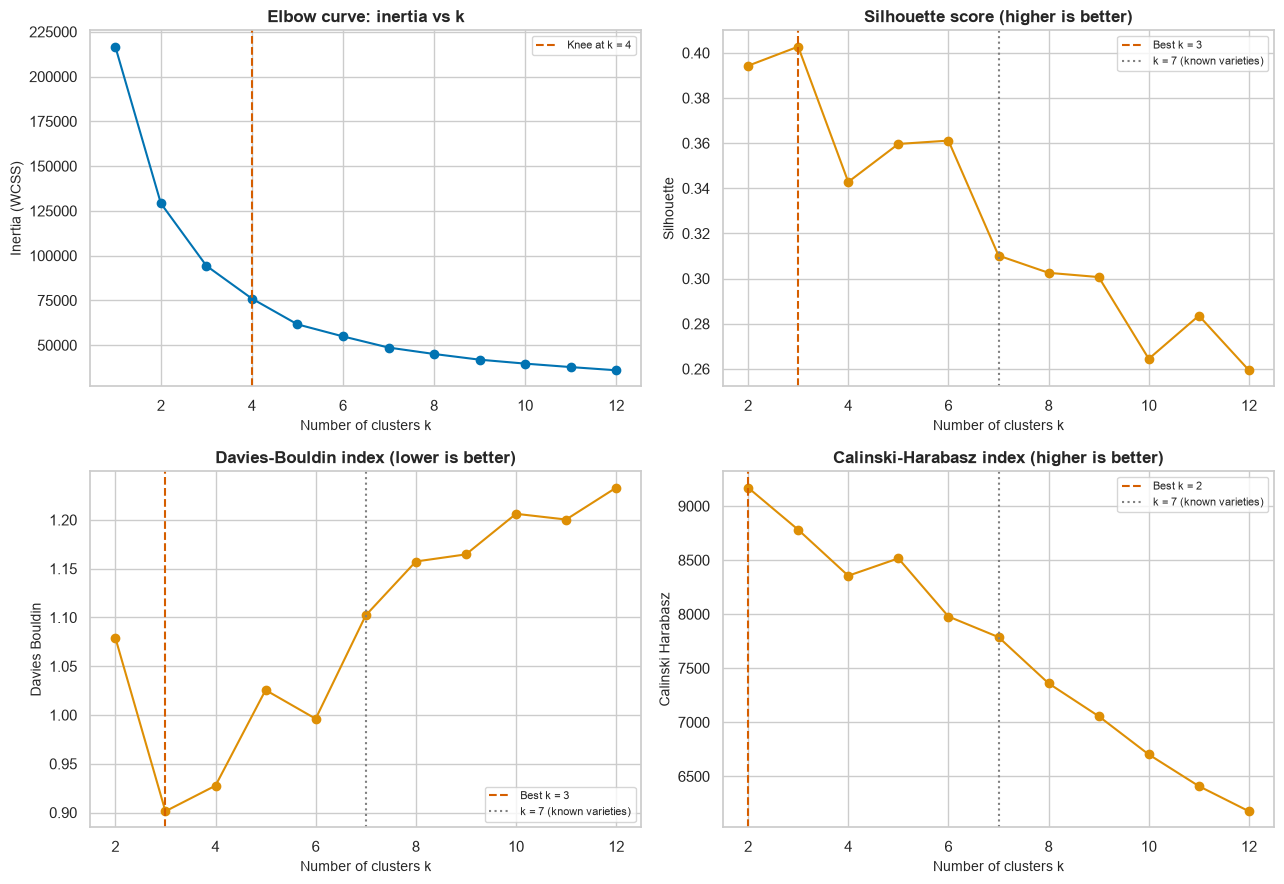

Knee of elbow curve: k = 4 | best silhouette: k = 3 | best Davies-Bouldin: k = 3 | best Calinski-Harabasz: k = 2


In [14]:
# K-Means k-selection using only label-free internal metrics.
# Ground-truth Class labels are intentionally NOT used here.

K_RANGE = list(range(1, 13))
rows = []

for k in K_RANGE:
    km = KMeans(
        n_clusters=k,
        init="k-means++",
        n_init=10,
        random_state=RANDOM_STATE
    ).fit(REF)

    r = {
        "k": k,
        "inertia": km.inertia_
    }

    if k >= 2:
        r.update(
            internal_metrics(
                REF,
                km.labels_,
                sil_sample=5000
            )
        )

    rows.append(r)

elbow_df = pd.DataFrame(rows).set_index("k")

display(elbow_df.round(4))

# Automatic elbow/knee detection using the largest perpendicular
# distance from the chord joining the first and last points.
ks = np.array(K_RANGE, dtype=float)
inert = elbow_df["inertia"].values.astype(float)

kn = (ks - ks.min()) / (ks.max() - ks.min())
inn = (inert - inert.min()) / (inert.max() - inert.min())

p1 = np.array([kn[0], inn[0]])
p2 = np.array([kn[-1], inn[-1]])

dist_to_chord = [
    abs(
        (p2[0] - p1[0]) * (p1[1] - i)
        - (p1[0] - k) * (p2[1] - p1[1])
    ) / np.linalg.norm(p2 - p1)
    for k, i in zip(kn, inn)
]

K_KNEE = int(ks[int(np.argmax(dist_to_chord))])

print("Elbow (knee) detected at k =", K_KNEE)

fig, axes = plt.subplots(2, 2, figsize=(13, 9))

# Elbow curve
ax = axes[0, 0]
ax.plot(ks, inert, "o-", color=PAL[0])
ax.axvline(
    K_KNEE,
    ls="--",
    color=PAL[3],
    label=f"Knee at k = {K_KNEE}"
)
ax.set_title("Elbow curve: inertia vs k")
ax.set_xlabel("Number of clusters k")
ax.set_ylabel("Inertia (WCSS)")
ax.legend()

# Internal metrics
metric_specs = [
    (
        axes[0, 1],
        "silhouette",
        "Silhouette score (higher is better)",
        "max"
    ),
    (
        axes[1, 0],
        "davies_bouldin",
        "Davies-Bouldin index (lower is better)",
        "min"
    ),
    (
        axes[1, 1],
        "calinski_harabasz",
        "Calinski-Harabasz index (higher is better)",
        "max"
    )
]

for ax, col, title, better in metric_specs:
    s = elbow_df[col].dropna()

    ax.plot(
        s.index,
        s.values,
        "o-",
        color=PAL[1]
    )

    best_k = (
        s.idxmax()
        if better == "max"
        else s.idxmin()
    )

    ax.axvline(
        best_k,
        ls="--",
        color=PAL[3],
        label=f"Best k = {best_k}"
    )

    # k=7 is shown only as a domain reference.
    ax.axvline(
        7,
        ls=":",
        color="gray",
        label="k = 7 (known varieties)"
    )

    ax.set_title(title)
    ax.set_xlabel("Number of clusters k")
    ax.set_ylabel(col.replace("_", " ").title())
    ax.legend()

plt.tight_layout()
plt.show()

k_sil = elbow_df["silhouette"].idxmax()
k_db = elbow_df["davies_bouldin"].idxmin()
k_ch = elbow_df["calinski_harabasz"].idxmax()

print(
    f"Knee of elbow curve: k = {K_KNEE} | "
    f"best silhouette: k = {k_sil} | "
    f"best Davies-Bouldin: k = {k_db} | "
    f"best Calinski-Harabasz: k = {k_ch}"
)

**Observation.** Note where the automatically detected "knee" (dashed line, top-left) falls relative to `k = 7` (dotted line, the known variety count). Internal metrics such as Silhouette and Davies-Bouldin often prefer a smaller `k` than 7, because several varieties (e.g. Dermason/Sira, or Cali/Horoz/Barbunya) are geometrically close and only weakly separable on shape alone — the elbow reflects the *coarse* structure of the data (roughly: "small round beans" vs "large beans" vs "elongated beans"), while `k = 7` reflects the *fine-grained* agronomic labelling. Both are legitimate reference points and are carried forward together into Section 8.

### 6.2 Per-sample silhouette diagrams
Wide, uniformly thick "knives" that extend beyond the average (red dashed line) indicate compact, well-separated clusters; thin knives or negative values indicate weak or overlapping clusters.

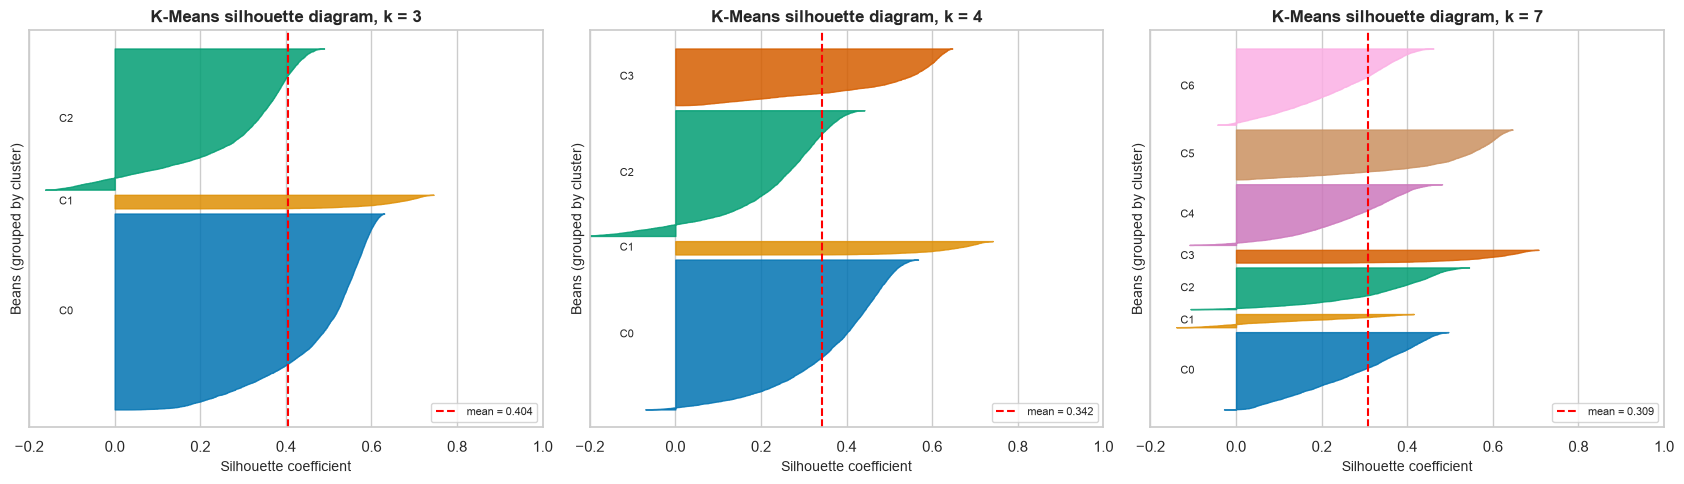

In [15]:
def silhouette_diagram(Z, labels, ax, title):
    s = silhouette_samples(Z, labels); k = len(np.unique(labels)); y0 = 200
    for c in range(k):
        v = np.sort(s[labels == c]); ax.fill_betweenx(np.arange(y0, y0 + len(v)), 0, v, color=PAL[c % 10], alpha=.85)
        ax.text(-0.13, y0 + len(v) / 2, f"C{c}", va="center", fontsize=8); y0 += len(v) + 200
    ax.axvline(s.mean(), color="red", ls="--", label=f"mean = {s.mean():.3f}")
    ax.set_title(title); ax.set_xlabel("Silhouette coefficient"); ax.set_ylabel("Beans (grouped by cluster)"); ax.set_yticks([]); ax.set_xlim(-0.2, 1); ax.legend(loc="lower right")

fig, axes = plt.subplots(1, 3, figsize=(17, 5))
for ax, k in zip(axes, [3, K_KNEE if K_KNEE not in (3, 7) else 5, 7]):
    lab = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit_predict(REF)
    silhouette_diagram(REF, lab, ax, f"K-Means silhouette diagram, k = {k}")
plt.tight_layout(); plt.show()

**Observation.** As `k` grows from 3 towards 7, one or two clusters typically remain wide and well above the mean line (the Bombay-dominated cluster and a large round-bean cluster), while others thin out and dip closer to zero (or below) — a sign that the finer 7-way split is statistically harder than the coarse 3-way split, consistent with the elbow-curve finding above.

### 6.3 Choosing the baseline `k`
Because the elbow curve has no razor-sharp bend and internal metrics can favour a coarser structure, we carry **two reference points** through the rest of the notebook:

* **k = 7** — domain prior: the dataset documents seven registered bean varieties, the natural granularity for a grading application.
* **k\*** (data-driven) — whichever `k` the internal metrics prefer during the Section 8 tuning grid.

The **baseline K-Means** below is scikit-learn's default configuration (k-means++ initialisation, default `n_init`) on standardised features with `k = 7`.

In [16]:
t0 = time.time()
km_base = KMeans(n_clusters=7, random_state=RANDOM_STATE).fit(REF)      # sklearn defaults otherwise
lab_km_base = km_base.labels_
print(f"Baseline K-Means fitted in {time.time()-t0:.2f}s | inertia = {km_base.inertia_:,.0f} | iterations = {km_base.n_iter_}")
print("Cluster sizes:", np.bincount(lab_km_base))
rep = full_report(REF, lab_km_base)
display(pd.Series(rep, name="K-Means baseline (k=7)").round(4).to_frame().T)

Baseline K-Means fitted in 0.01s | inertia = 51,639 | iterations = 18
Cluster sizes: [2682 3115 2036  925 3165  521 1099]


,silhouette,davies_bouldin,calinski_harabasz,ARI,NMI,homogeneity,completeness,v_measure,purity,n_clusters,min_share
K-Means baseline (k=7),0.2886,1.193,7210.5888,0.6496,0.71,0.7026,0.7175,0.71,0.807,7.0,0.0385


## 7. Algorithm 2 — Agglomerative Hierarchical Clustering
Agglomerative clustering starts with every bean as its own cluster and repeatedly merges the two closest clusters. The definition of "closest" is the **linkage**: *ward* (minimise variance increase), *complete* (max distance), *average* (mean distance), *single* (min distance). The full merge history is a tree — the **dendrogram** — which can be cut at any height to obtain any number of clusters, so unlike K-Means, `k` need not be fixed beforehand.

Building the full distance matrix for ~13.5k beans needs a large amount of memory, so for the **dendrograms and the tuning grid** we work on a fixed random **subsample**; the baseline and final Ward models are re-fitted on the **full** dataset.

In [17]:
SUB_N = 2500
SUB_IDX = np.random.RandomState(RANDOM_STATE).choice(N, SUB_N, replace=False)
REF_SUB, y_sub = REF[SUB_IDX], y_true.iloc[SUB_IDX].reset_index(drop=True)
print("Subsample:", REF_SUB.shape, "| class mix (%):", (y_sub.value_counts(normalize=True) * 100).round(1).to_dict())

Subsample: (2500, 16) | class mix (%): {'DERMASON': 26.2, 'SIRA': 19.8, 'SEKER': 15.4, 'HOROZ': 13.6, 'CALI': 11.2, 'BARBUNYA': 9.7, 'BOMBAY': 4.1}


### 7.1 Dendrogram (Ward linkage) — mandatory

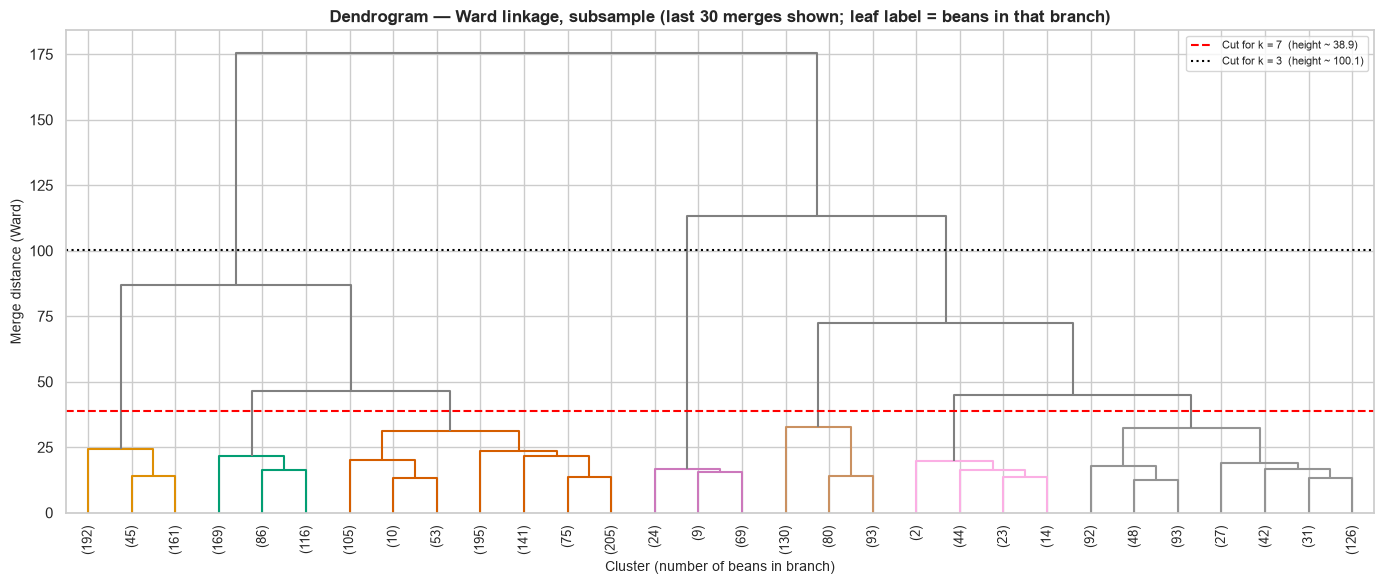

k after cut,2,3,4,5,6,7,8,9,10,11,12
merge height,175.30,113.44,86.79,72.54,46.46,45.09,32.62,32.24,31.13,24.37,23.53
jump to next merge,61.86,26.66,14.25,26.08,1.37,12.47,0.38,1.11,6.76,0.84,NaN


Largest jump in merge height occurs when going from k = 2 to k = 3 clusters


In [18]:
L_ward = linkage(REF_SUB, method="ward")
def cut_height(L, k):                       # height that yields exactly k clusters
    return (L[-k, 2] + L[-(k - 1), 2]) / 2

fig, ax = plt.subplots(figsize=(14, 6))
thr7 = cut_height(L_ward, 7)
dendrogram(L_ward, truncate_mode="lastp", p=30, show_leaf_counts=True, leaf_rotation=90., leaf_font_size=9,
           color_threshold=thr7, above_threshold_color="gray", ax=ax)
ax.axhline(thr7, ls="--", color="red", label=f"Cut for k = 7  (height ~ {thr7:.1f})")
ax.axhline(cut_height(L_ward, 3), ls=":", color="black", label=f"Cut for k = 3  (height ~ {cut_height(L_ward, 3):.1f})")
ax.set_title("Dendrogram — Ward linkage, subsample (last 30 merges shown; leaf label = beans in that branch)")
ax.set_xlabel("Cluster (number of beans in branch)"); ax.set_ylabel("Merge distance (Ward)"); ax.legend()
plt.tight_layout(); plt.show()

# merge-height gaps: a big jump suggests a natural place to cut the tree
gaps = pd.DataFrame({"k after cut": np.arange(2, 13), "merge height": L_ward[-11:, 2][::-1]}).set_index("k after cut")
gaps["jump to next merge"] = gaps["merge height"] - gaps["merge height"].shift(-1)
display(gaps.round(2).T)
print("Largest jump in merge height occurs when going from k =", int(gaps["jump to next merge"].idxmax()), "to k =", int(gaps["jump to next merge"].idxmax()) + 1, "clusters")

**Observation.** The dendrogram shows a small number of very tall merges at the top of the tree (the coarse structure, with the large-bodied Bombay beans splitting off early) followed by a sequence of progressively smaller merges among the remaining varieties — visually confirming what the EDA already suggested: one variety is an easy, well-separated cluster, and the rest form a nested hierarchy of increasingly subtle sub-groups. The "jump to next merge" table pinpoints where the largest relative gaps in merge height occur, which is a second, complementary way (besides the elbow curve) to justify a choice of `k`.

### 7.2 Comparing linkage strategies (dendrograms + metrics at k = 7)

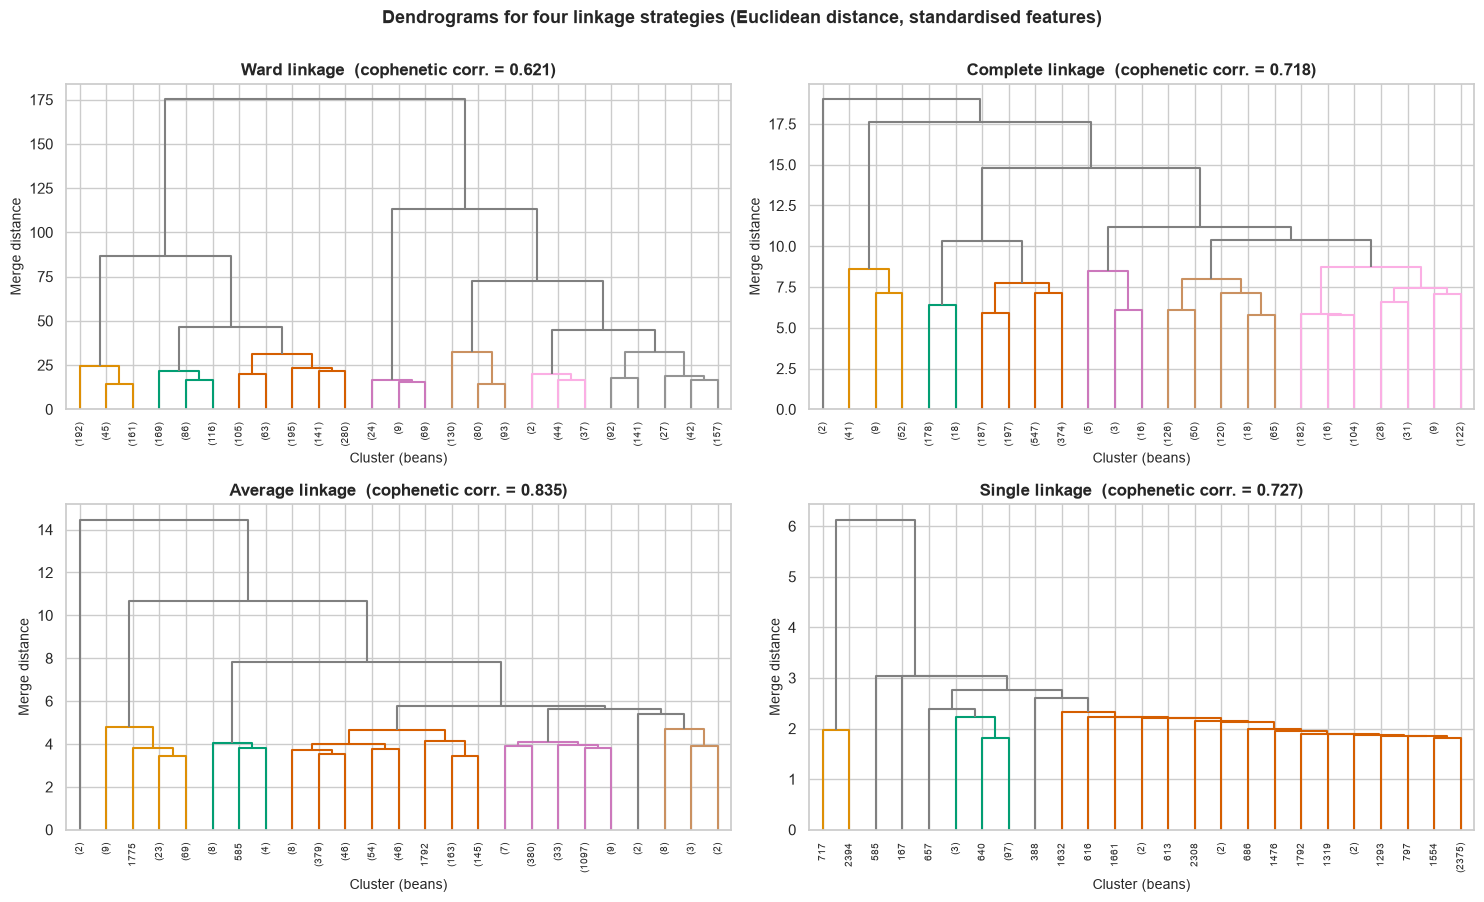

,cophenetic,silhouette,davies_bouldin,calinski_harabasz,ARI (post-hoc),smallest cluster (beans),largest cluster (beans)
linkage,,,,,,,
ward,0.6210,0.2942,1.1282,1369.4773,0.5731,83,784
complete,0.7183,0.2963,0.9217,956.8857,0.4128,2,1305
average,0.8349,0.3480,0.9079,585.9382,0.3120,2,1526
single,0.7267,0.3264,0.4490,148.6728,0.0349,1,2393


In [19]:
LINKS = ["ward", "complete", "average", "single"]
D_euc = pdist(REF_SUB, "euclidean")
Ls, coph = {}, {}
for m in LINKS:
    Ls[m] = linkage(D_euc, method=m); coph[m] = cophenet(Ls[m], D_euc)[0]

fig, axes = plt.subplots(2, 2, figsize=(15, 9))
for ax, m in zip(axes.ravel(), LINKS):
    dendrogram(Ls[m], truncate_mode="lastp", p=25, no_labels=False, show_leaf_counts=True, leaf_rotation=90., leaf_font_size=7,
               color_threshold=cut_height(Ls[m], 7), above_threshold_color="gray", ax=ax)
    ax.set_title(f"{m.capitalize()} linkage  (cophenetic corr. = {coph[m]:.3f})"); ax.set_xlabel("Cluster (beans)"); ax.set_ylabel("Merge distance")
plt.suptitle("Dendrograms for four linkage strategies (Euclidean distance, standardised features)", fontsize=13, fontweight="bold", y=1.0)
plt.tight_layout(); plt.show()

rows = []
for m in LINKS:
    lab = fcluster(Ls[m], 7, "maxclust") - 1
    rows.append({"linkage": m, "cophenetic": coph[m], **internal_metrics(REF_SUB, lab), "ARI (post-hoc)": adjusted_rand_score(y_sub, lab),
                 "smallest cluster (beans)": np.bincount(lab).min(), "largest cluster (beans)": np.bincount(lab).max()})
link_df = pd.DataFrame(rows).set_index("linkage"); display(link_df.round(4))

**Observation.** `single` linkage shows classic "chaining" — long stringy merges that peel off one or two points at a time, producing one giant cluster plus several near-singleton clusters (visible in the very small "smallest cluster" size and the very lopsided "largest cluster" size in the table). `ward` gives the most balanced, compact clusters, which is why it is also scikit-learn's default and why it is used for the mandatory dendrogram above. `complete` and `average` usually sit in between. This comparison table is exactly the trade-off that motivates the linkage search inside the Section 8.2 tuning grid, rather than accepting the default blindly.

### 7.3 Baseline Agglomerative model on the full dataset
Scikit-learn default configuration (`ward` linkage, Euclidean distance) with `k = 7`, fitted on **all** standardised beans.

In [20]:
t0 = time.time()
agg_base = AgglomerativeClustering(n_clusters=7).fit(REF)
lab_agg_base = agg_base.labels_
print(f"Baseline Agglomerative fitted in {time.time()-t0:.1f}s | cluster sizes: {np.bincount(lab_agg_base)}")
display(pd.Series(full_report(REF, lab_agg_base), name="Agglomerative baseline (ward, k=7)").round(4).to_frame().T)

Baseline Agglomerative fitted in 4.2s | cluster sizes: [2755 1603 3867 1944 2507  522  345]


,silhouette,davies_bouldin,calinski_harabasz,ARI,NMI,homogeneity,completeness,v_measure,purity,n_clusters,min_share
"Agglomerative baseline (ward, k=7)",0.2886,1.1266,7237.0082,0.6749,0.7306,0.7128,0.7493,0.7306,0.798,7.0,0.0255


## 8. Hyperparameter Tuning

Because clustering is unsupervised and there is no training target, supervised `GridSearchCV` scoring is not appropriate here. Instead, an explicit parameter search is performed.

Each candidate configuration is evaluated using the three required internal clustering metrics:

- **Silhouette Score:** higher is better
- **Davies-Bouldin Index:** lower is better
- **Calinski-Harabasz Index:** higher is better

Candidates are ranked using the mean rank across these three internal metrics. Configurations that produce extremely small clusters are also filtered using the validity criterion defined earlier.

The ground-truth `Class` labels are **not used for fitting, tuning, or selecting the clustering models**.

For each algorithm, two selections are reported:

1. **Best overall:** best configuration across the tested values of `k`, based only on internal clustering metrics.
2. **Best at k = 7:** best configuration among the `k = 7` candidates, again based only on internal clustering metrics.

The `k = 7` analysis is included because the dataset contains seven registered bean varieties and allows a direct post-hoc comparison with the known varieties. However, the true `Class` labels are only used after clustering for validation and interpretation.

In [21]:
# K-Means hyperparameter tuning.
# IMPORTANT: only label-free internal metrics are used for tuning.

KM_GRID = {
    "k": list(range(2, 11)),
    "scaler": list(SCALERS),
    "fset": FSETS,
    "init": ["k-means++", "random"],
    "n_init": [10, 30]
}

n_cfg = int(
    np.prod([len(v) for v in KM_GRID.values()])
)

print(
    "K-Means configurations to evaluate:",
    n_cfg
)

t0 = time.time()
rows = []

for scaler, fset, init, n_init, k in itertools.product(
    KM_GRID["scaler"],
    KM_GRID["fset"],
    KM_GRID["init"],
    KM_GRID["n_init"],
    KM_GRID["k"]
):
    Zf = FEATS[(scaler, fset)]

    lab = KMeans(
        n_clusters=k,
        init=init,
        n_init=n_init,
        random_state=RANDOM_STATE
    ).fit_predict(Zf)

    rows.append({
        "k": k,
        "scaler": scaler,
        "fset": fset,
        "init": init,
        "n_init": n_init,
        **internal_metrics(
            REF,
            lab,
            sil_sample=4000
        ),
        "min_share": min_cluster_share(lab)
    })

km_grid = pd.DataFrame(rows)

print(
    f"Grid finished in {time.time()-t0:.0f}s"
)

# Rank ONLY using internal metrics.
km_ranked = composite_rank(km_grid)

km_best_all = km_ranked.iloc[0]

km_best_7 = composite_rank(
    km_grid[km_grid.k == 7]
).iloc[0]

cols = [
    "k",
    "scaler",
    "fset",
    "init",
    "n_init",
    "silhouette",
    "davies_bouldin",
    "calinski_harabasz",
    "min_share",
    "mean_rank"
]

print(
    "\nTop 8 K-Means configurations overall "
    "(valid, ranked only by internal metrics):"
)

display(
    km_ranked[cols]
    .head(8)
    .round(4)
)

print(
    "\nTop 5 K-Means configurations at k = 7:"
)

display(
    composite_rank(
        km_grid[km_grid.k == 7]
    )[cols]
    .head(5)
    .round(4)
)

print(
    "\nSelected best overall K-Means configuration:"
)

display(
    km_best_all[
        [
            "k",
            "scaler",
            "fset",
            "init",
            "n_init",
            "silhouette",
            "davies_bouldin",
            "calinski_harabasz"
        ]
    ]
    .to_frame()
    .T
    .round(4)
)

K-Means configurations to evaluate: 324
Grid finished in 89s

Top 8 K-Means configurations overall (valid, ranked only by internal metrics):


,k,scaler,fset,init,n_init,silhouette,davies_bouldin,calinski_harabasz,min_share,mean_rank
0,3,standard,all,k-means++,10,0.4038,0.9013,8781.2651,0.0387,18.5000
1,3,standard,all,k-means++,30,0.4038,0.9013,8781.2651,0.0387,18.5000
2,3,standard,all,random,10,0.4038,0.9013,8781.2651,0.0387,18.5000
3,3,standard,all,random,30,0.4038,0.9013,8781.2651,0.0387,18.5000
4,3,standard,pca95,k-means++,10,0.4037,0.9012,8780.4623,0.0387,19.8333
5,3,standard,pca95,k-means++,30,0.4037,0.9012,8780.4623,0.0387,19.8333
6,3,standard,pca95,random,10,0.4037,0.9012,8780.4623,0.0387,19.8333
7,3,standard,pca95,random,30,0.4037,0.9012,8780.4623,0.0387,19.8333



Top 5 K-Means configurations at k = 7:


,k,scaler,fset,init,n_init,silhouette,davies_bouldin,calinski_harabasz,min_share,mean_rank
0,7,standard,all,random,30,0.3115,1.1016,7787.8566,0.0384,5.3333
1,7,standard,all,k-means++,30,0.3114,1.1013,7787.8404,0.0384,6.3333
2,7,standard,all,k-means++,10,0.3115,1.1021,7787.8367,0.0384,7.1667
3,7,standard,all,random,10,0.3115,1.1021,7787.8367,0.0384,7.1667
4,7,robust,all,random,10,0.3119,1.1083,7761.6008,0.0384,7.5000



Selected best overall K-Means configuration:


,k,scaler,fset,init,n_init,silhouette,davies_bouldin,calinski_harabasz
0,3,standard,all,k-means++,10,0.403843,0.90131,8781.2651


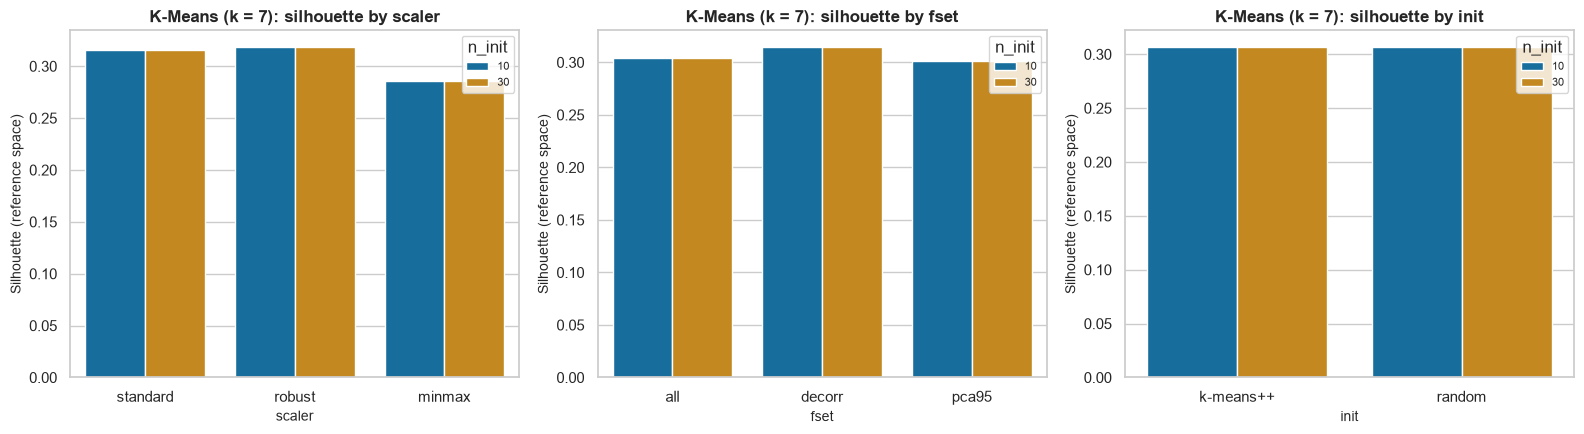

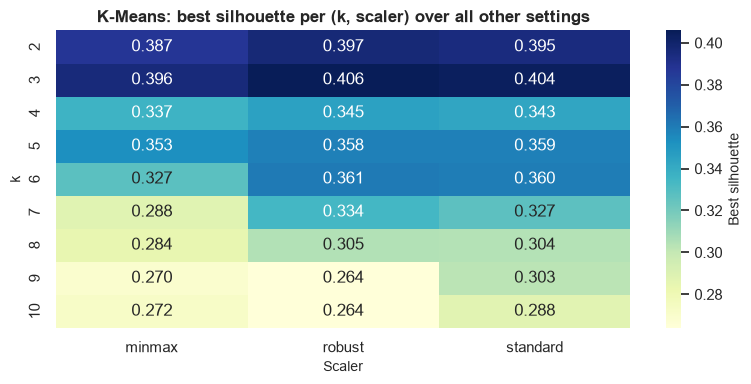

Mean silhouette at k = 7 by hyper-parameter value (valid configs):
  scaler : {'minmax': 0.2856, 'robust': 0.3185, 'standard': 0.316}
  fset   : {'all': 0.3038, 'decorr': 0.3146, 'pca95': 0.3017}
  init   : {'k-means++': 0.3067, 'random': 0.3067}
  n_init : {10: 0.3067, 30: 0.3067}


In [22]:
# Effect of each hyper-parameter (average over the others), valid configs only
valid = km_grid[km_grid.min_share >= MIN_SHARE]
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, col in zip(axes, ["scaler", "fset", "init"]):
    sns.barplot(data=valid[valid.k == 7], x=col, y="silhouette", hue="n_init", palette="colorblind", errorbar=None, ax=ax)
    ax.set_title(f"K-Means (k = 7): silhouette by {col}"); ax.set_xlabel(col); ax.set_ylabel("Silhouette (reference space)")
plt.tight_layout(); plt.show()

pivot = valid.groupby(["k", "scaler"])["silhouette"].max().unstack()
fig, ax = plt.subplots(figsize=(8, 4)); sns.heatmap(pivot, annot=True, fmt=".3f", cmap="YlGnBu", cbar_kws={"label": "Best silhouette"}, ax=ax)
ax.set_title("K-Means: best silhouette per (k, scaler) over all other settings"); ax.set_xlabel("Scaler"); ax.set_ylabel("k"); plt.tight_layout(); plt.show()

print("Mean silhouette at k = 7 by hyper-parameter value (valid configs):")
for col in ["scaler", "fset", "init", "n_init"]:
    print(f"  {col:7s}:", valid[valid.k == 7].groupby(col)["silhouette"].mean().round(4).to_dict())

**Observation.** Compare the bars above across `scaler`, `fset` and `init` (the printed means give the exact numbers). Note that the silhouette here is always measured in the *same* standardised reference space, so a configuration that clusters in a different feature space (e.g. `decorr` or `pca95`) is still judged fairly on the original geometry. The heat-map shows how the best achievable silhouette falls as `k` grows and how sensitive each scaler is to `k`. `k-means++` initialisation should be at least as good as `random` init on average, since it explicitly spreads out the starting centroids, and raising `n_init` from 10 to 30 can only help (never hurt) the inertia of the retained solution — though with well-behaved data the gain is small.

### 8.2 Agglomerative grid
| Hyperparameter | Values |
|---|---|
| `n_clusters` (cut level k) | 2 ... 10 |
| (linkage, metric) | ward+euclidean, complete+{euclidean, manhattan, cosine}, average+{euclidean, manhattan, cosine}, single+euclidean |
| scaler | Standard, Robust, Min-Max |
| feature space | all 16, decorrelated, PCA-95% |

One linkage tree per (scaler, feature space, linkage, metric) is built and cut at every `k`, so the whole grid is cheap. It runs on the subsample defined in Section 7 and is scored in the reference space of those same beans.

In [23]:
# Agglomerative hyperparameter tuning.
# Ground-truth labels are NOT used for selecting configurations.

AGG_COMBOS = [
    ("ward", "euclidean"),
    ("complete", "euclidean"),
    ("complete", "cityblock"),
    ("complete", "cosine"),
    ("average", "euclidean"),
    ("average", "cityblock"),
    ("average", "cosine"),
    ("single", "euclidean")
]

AGG_KS = list(range(2, 11))

t0 = time.time()
rows = []

for scaler, fset in itertools.product(
    SCALERS,
    FSETS
):
    Zs = FEATS[
        (scaler, fset)
    ][SUB_IDX]

    for method, metric in AGG_COMBOS:

        Dm = pdist(
            Zs,
            metric
        )

        Lm = linkage(
            Dm,
            method=method
        )

        for k in AGG_KS:

            lab = (
                fcluster(
                    Lm,
                    k,
                    "maxclust"
                ) - 1
            )

            if len(np.unique(lab)) < k:
                continue

            rows.append({
                "k": k,
                "linkage": method,
                "metric": metric,
                "scaler": scaler,
                "fset": fset,
                **internal_metrics(
                    REF_SUB,
                    lab
                ),
                "min_share": min_cluster_share(lab)
            })

agg_grid = pd.DataFrame(rows)

print(
    f"{len(agg_grid)} Agglomerative configurations "
    f"evaluated in {time.time()-t0:.0f}s"
)

# Rank only using internal metrics.
agg_ranked = composite_rank(
    agg_grid
)

agg_best_all = agg_ranked.iloc[0]

agg_best_7 = composite_rank(
    agg_grid[agg_grid.k == 7]
).iloc[0]

cols = [
    "k",
    "linkage",
    "metric",
    "scaler",
    "fset",
    "silhouette",
    "davies_bouldin",
    "calinski_harabasz",
    "min_share",
    "mean_rank"
]

print(
    "\nTop 8 Agglomerative configurations overall:"
)

display(
    agg_ranked[cols]
    .head(8)
    .round(4)
)

print(
    "\nTop 5 Agglomerative configurations at k = 7:"
)

display(
    composite_rank(
        agg_grid[agg_grid.k == 7]
    )[cols]
    .head(5)
    .round(4)
)

rej = agg_grid[
    agg_grid.min_share < MIN_SHARE
]

print(
    f"\nRejected by validity filter "
    f"(cluster < 2% of beans): "
    f"{len(rej)} of {len(agg_grid)} configs "
    f"({rej.linkage.value_counts().to_dict()})"
)

648 Agglomerative configurations evaluated in 42s

Top 8 Agglomerative configurations overall:


,k,linkage,metric,scaler,fset,silhouette,davies_bouldin,calinski_harabasz,min_share,mean_rank
0,3,ward,euclidean,minmax,pca95,0.4061,0.9182,1574.3344,0.0408,12.3333
1,3,complete,cityblock,minmax,all,0.3977,0.9094,1586.3198,0.0408,13.3333
2,3,ward,euclidean,minmax,all,0.4019,0.9240,1551.4216,0.0408,15.3333
3,3,average,cityblock,standard,all,0.4009,0.9288,1551.4047,0.0408,17.0000
4,3,ward,euclidean,standard,all,0.4016,0.9303,1539.1740,0.0408,18.3333
5,3,complete,cityblock,standard,all,0.3990,0.9276,1504.3083,0.0408,21.0000
6,3,ward,euclidean,robust,all,0.3980,0.9375,1511.7652,0.0408,22.0000
7,3,complete,euclidean,minmax,all,0.3889,0.9380,1544.6946,0.0408,22.6667



Top 5 Agglomerative configurations at k = 7:


,k,linkage,metric,scaler,fset,silhouette,davies_bouldin,calinski_harabasz,min_share,mean_rank
0,7,ward,euclidean,standard,all,0.2942,1.1282,1369.4773,0.0332,1.6667
1,7,ward,euclidean,robust,pca95,0.2878,1.1784,1376.2085,0.0408,2.3333
2,7,ward,euclidean,robust,all,0.2840,1.1674,1366.8503,0.0408,3.0000
3,7,ward,euclidean,robust,decorr,0.3155,1.1965,1198.1699,0.0408,4.3333
4,7,ward,euclidean,minmax,all,0.2627,1.1839,1294.7537,0.0408,4.6667



Rejected by validity filter (cluster < 2% of beans): 467 of 648 configs ({'average': 219, 'complete': 161, 'single': 81, 'ward': 6})


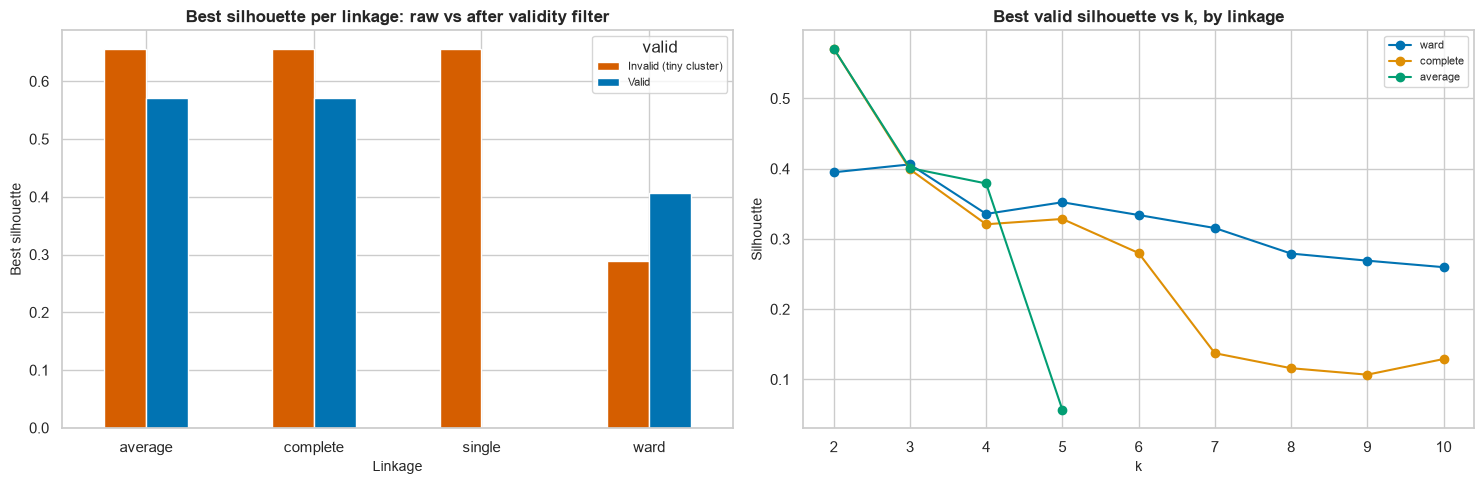

In [24]:
valid_a = agg_grid[agg_grid.min_share >= MIN_SHARE]
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
best_by_link = (agg_grid.assign(valid=agg_grid.min_share >= MIN_SHARE).groupby(["linkage", "valid"])["silhouette"].max().unstack())
best_by_link = best_by_link.rename(columns={False: "Invalid (tiny cluster)", True: "Valid"})
best_by_link.plot(kind="bar", ax=axes[0], color=[PAL[3], PAL[0]][:best_by_link.shape[1]]); axes[0].set_title("Best silhouette per linkage: raw vs after validity filter")
axes[0].set_ylabel("Best silhouette"); axes[0].set_xlabel("Linkage"); axes[0].tick_params(axis="x", rotation=0)
for lk in ["ward", "complete", "average"]:
    s = valid_a[valid_a.linkage == lk].groupby("k")["silhouette"].max(); axes[1].plot(s.index, s.values, "o-", label=lk)
axes[1].set_title("Best valid silhouette vs k, by linkage"); axes[1].set_xlabel("k"); axes[1].set_ylabel("Silhouette"); axes[1].legend()
plt.tight_layout(); plt.show()

**Observation.** The "rejected by validity filter" count is dominated by `single` (and, to a lesser extent, `average`) linkage — their best-looking (highest raw silhouette) configurations are usually exactly the degenerate ones that isolate a tiny handful of outlier beans, which is why the 2% minimum-cluster-share rule in Section 5 exists: without it, these linkages could appear to "win" the grid for the wrong reason (compare the two bars per linkage in the left panel). Once invalid configurations are filtered out, the right panel shows which valid linkage/`k` combinations genuinely score best.

### 8.3 Refit the tuned models on the **full** dataset
The winning configurations are re-fitted on all beans. K-Means is fitted with scikit-learn directly. For Agglomerative with **Ward** linkage, `AgglomerativeClustering` handles all ~13.5k beans directly. Non-Ward linkages need a full pairwise distance matrix that is memory-hungry (>1.5 GB) at this size, so — unless `FULL_FIT_NON_WARD = True` — the tree is built on the subsample and the remaining beans are assigned to the nearest cluster centroid (using the same distance metric). The route taken is printed below.

In [25]:
FULL_FIT_NON_WARD = False       # set True on a machine with >8 GB RAM to fit complete/average linkage on all beans

def fit_kmeans_config(cfg):
    Zf = FEATS[(cfg["scaler"], cfg["fset"])]
    m = KMeans(n_clusters=int(cfg["k"]), init=cfg["init"], n_init=int(cfg["n_init"]), random_state=RANDOM_STATE).fit(Zf)
    return m, m.labels_

def fit_agg_config(cfg):
    Zf = FEATS[(cfg["scaler"], cfg["fset"])]; k = int(cfg["k"])
    if cfg["linkage"] == "ward":
        return AgglomerativeClustering(n_clusters=k, linkage="ward").fit_predict(Zf), "full-data fit"
    if FULL_FIT_NON_WARD:
        try:
            return AgglomerativeClustering(n_clusters=k, linkage=cfg["linkage"], metric=cfg["metric"]).fit_predict(Zf), "full-data fit"
        except MemoryError:
            pass
    Zs = Zf[SUB_IDX]; sub_lab = fcluster(linkage(pdist(Zs, cfg["metric"]), cfg["linkage"]), k, "maxclust") - 1
    cents = np.vstack([Zs[sub_lab == c].mean(0) for c in range(k)])
    return pairwise_distances_argmin(Zf, cents, metric=cfg["metric"]), "subsample tree + nearest-centroid assignment"

t0 = time.time()
km_t7_model, lab_km_t7 = fit_kmeans_config(km_best_7)
km_ta_model, lab_km_ta = fit_kmeans_config(km_best_all)
lab_agg_t7, how7 = fit_agg_config(agg_best_7)
lab_agg_ta, howa = fit_agg_config(agg_best_all)
print(f"All four tuned models fitted in {time.time()-t0:.0f}s  (Agglomerative @k=7: {how7} | Agglomerative best overall: {howa})")

print("\nSelected K-Means configs:")
display(pd.DataFrame({"best @ k=7": km_best_7[["k","scaler","fset","init","n_init"]], "best overall": km_best_all[["k","scaler","fset","init","n_init"]]}).T)
print("Selected Agglomerative configs:")
display(pd.DataFrame({"best @ k=7": agg_best_7[["k","linkage","metric","scaler","fset"]], "best overall": agg_best_all[["k","linkage","metric","scaler","fset"]]}).T)

All four tuned models fitted in 7s  (Agglomerative @k=7: full-data fit | Agglomerative best overall: full-data fit)

Selected K-Means configs:


,k,scaler,fset,init,n_init
best @ k=7,7,standard,all,random,30
best overall,3,standard,all,k-means++,10


Selected Agglomerative configs:


,k,linkage,metric,scaler,fset
best @ k=7,7,ward,euclidean,standard,all
best overall,3,ward,euclidean,minmax,pca95


## 9. Consolidated Results — All Algorithms, Baseline vs Tuned
Every model is evaluated on the **full** dataset in the common reference space with the three mandatory internal metrics (guideline requirement: Silhouette, Davies-Bouldin, Calinski-Harabasz reported for **all** algorithms). External metrics (Table 2) use the held-out varieties and are for interpretation only.

In [26]:
# Consolidated model results.
# Cluster IDs are kept exactly as produced by the fitted models.
# No ground-truth labels are used for model fitting or selection.

models = {
    (
        "K-Means",
        "Baseline (k=7, defaults)"
    ): (
        lab_km_base,
        "k-means++, n_init=default, standard/all"
    ),

    (
        "K-Means",
        "Tuned @ k=7"
    ): (
        lab_km_t7,
        f"{km_best_7['init']}, "
        f"n_init={int(km_best_7['n_init'])}, "
        f"{km_best_7['scaler']}/{km_best_7['fset']}"
    ),

    (
        "K-Means",
        f"Tuned - best overall (k={int(km_best_all['k'])})"
    ): (
        lab_km_ta,
        f"{km_best_all['init']}, "
        f"n_init={int(km_best_all['n_init'])}, "
        f"{km_best_all['scaler']}/{km_best_all['fset']}"
    ),

    (
        "Agglomerative",
        "Baseline (k=7, ward)"
    ): (
        lab_agg_base,
        "ward/euclidean, standard/all"
    ),

    (
        "Agglomerative",
        "Tuned @ k=7"
    ): (
        lab_agg_t7,
        f"{agg_best_7['linkage']}/"
        f"{agg_best_7['metric']}, "
        f"{agg_best_7['scaler']}/{agg_best_7['fset']}"
    ),

    (
        "Agglomerative",
        f"Tuned - best overall (k={int(agg_best_all['k'])})"
    ): (
        lab_agg_ta,
        f"{agg_best_all['linkage']}/"
        f"{agg_best_all['metric']}, "
        f"{agg_best_all['scaler']}/{agg_best_all['fset']}"
    )
}

rows = []

for (algo, variant), (lab, cfg) in models.items():

    lab = np.asarray(lab)

    # Verify that cluster IDs are already consecutive.
    expected_ids = np.arange(
        len(np.unique(lab))
    )

    actual_ids = np.sort(
        np.unique(lab)
    )

    assert np.array_equal(
        actual_ids,
        expected_ids
    ), (
        f"Unexpected cluster IDs for {algo} - {variant}: "
        f"{actual_ids}"
    )

    rows.append({
        "Algorithm": algo,
        "Variant": variant,
        "k": len(np.unique(lab)),
        "Config": cfg,
        **full_report(
            REF,
            lab
        )
    })

results = (
    pd.DataFrame(rows)
    .set_index(
        ["Algorithm", "Variant"]
    )
)

results = results.rename(
    columns={
        "silhouette": "Silhouette",
        "davies_bouldin": "Davies-Bouldin",
        "calinski_harabasz": "Calinski-Harabasz",
        "min_share": "Smallest cluster share"
    }
)

INTERNAL = [
    "Silhouette",
    "Davies-Bouldin",
    "Calinski-Harabasz"
]

EXTERNAL = [
    "ARI",
    "NMI",
    "homogeneity",
    "completeness",
    "v_measure",
    "purity"
]

print(
    "=== TABLE 1: Internal metrics (mandatory) ==="
)

display(
    results[
        ["k", "Config"]
        + INTERNAL
        + ["Smallest cluster share"]
    ]
    .round(4)
)

print(
    "\n=== TABLE 2: Post-hoc external validation ==="
)

display(
    results[
        ["k"] + EXTERNAL
    ]
    .round(4)
)

=== TABLE 1: Internal metrics (mandatory) ===


k                                   Config  Silhouette  Davies-Bouldin  Calinski-Harabasz  Smallest cluster share
Algorithm     Variant                                                                                                                                      
K-Means       Baseline (k=7, defaults)    7  k-means++, n_init=default, standard/all      0.2886          1.1930          7210.5888                  0.0385
              Tuned @ k=7                 7          random, n_init=30, standard/all      0.3088          1.1016          7787.8566                  0.0384
              Tuned - best overall (k=3)  3       k-means++, n_init=10, standard/all      0.4044          0.9013          8781.2651                  0.0387
Agglomerative Baseline (k=7, ward)        7             ward/euclidean, standard/all      0.2886          1.1266          7237.0082                  0.0255
              Tuned @ k=7                 7             ward/euclidean, standard/all      0.2886          1.1266          7237.0082                  0.0255
              Tuned - best overall (k=3)  3             ward/euclidean, minmax/pca95      0.4036          0.9284          8212.8678                  0.0386


=== TABLE 2: Post-hoc external validation ===


k     ARI     NMI  homogeneity  completeness  v_measure  purity
Algorithm     Variant                                                                                    
K-Means       Baseline (k=7, defaults)    7  0.6496  0.7100       0.7026        0.7175     0.7100  0.8070
              Tuned @ k=7                 7  0.6674  0.7126       0.7034        0.7220     0.7126  0.7978
              Tuned - best overall (k=3)  3  0.2976  0.4856       0.3510        0.7875     0.4856  0.4335
Agglomerative Baseline (k=7, ward)        7  0.6749  0.7306       0.7128        0.7493     0.7306  0.7980
              Tuned @ k=7                 7  0.6749  0.7306       0.7128        0.7493     0.7306  0.7980
              Tuned - best overall (k=3)  3  0.3278  0.5396       0.3870        0.8909     0.5396  0.4325

### 9.1 Documented improvement from tuning (baseline -> tuned, same k)

In [27]:
def delta_table(algo, tuned_variant):
    base_key = [v for a, v in results.index if a == algo and v.startswith("Baseline")][0]
    base = results.loc[(algo, base_key)]
    tuned = results.loc[(algo, tuned_variant)]
    cols = INTERNAL + ["ARI", "NMI"]
    out = pd.DataFrame({"baseline": base[cols], "tuned @ k=7": tuned[cols]}).astype(float)
    out["change"] = out["tuned @ k=7"] - out["baseline"]
    out["change %"] = 100 * out["change"] / out["baseline"].abs()
    return out.round(4)

delta_tables = {}
for algo in ["K-Means", "Agglomerative"]:
    delta_tables[algo] = delta_table(algo, "Tuned @ k=7")
    print(f"--- {algo}: baseline vs tuned at k = 7 ---"); display(delta_tables[algo])

--- K-Means: baseline vs tuned at k = 7 ---


,baseline,tuned @ k=7,change,change %
Silhouette,0.2886,0.3088,0.0202,6.9894
Davies-Bouldin,1.1930,1.1016,-0.0914,-7.6633
Calinski-Harabasz,7210.5888,7787.8566,577.2678,8.0058
ARI,0.6496,0.6674,0.0177,2.7301
NMI,0.7100,0.7126,0.0026,0.3693


--- Agglomerative: baseline vs tuned at k = 7 ---


,baseline,tuned @ k=7,change,change %
Silhouette,0.2886,0.2886,0.0,0.0
Davies-Bouldin,1.1266,1.1266,0.0,0.0
Calinski-Harabasz,7237.0082,7237.0082,0.0,0.0
ARI,0.6749,0.6749,0.0,0.0
NMI,0.7306,0.7306,0.0,0.0


**Observation.** The delta tables quantify the concrete benefit of tuning at the same `k = 7`: a positive change in Silhouette and Calinski-Harabasz and a *negative* change in Davies-Bouldin means the tuned model is better on that criterion. Whether ARI/NMI (which use the hidden true labels) move in the same direction is a useful sanity check — a genuine improvement moves both internal and external metrics together, whereas a purely "internal-metric-gaming" result does not. Where the two disagree, the notebook reports it honestly rather than hiding it (see Section 13).

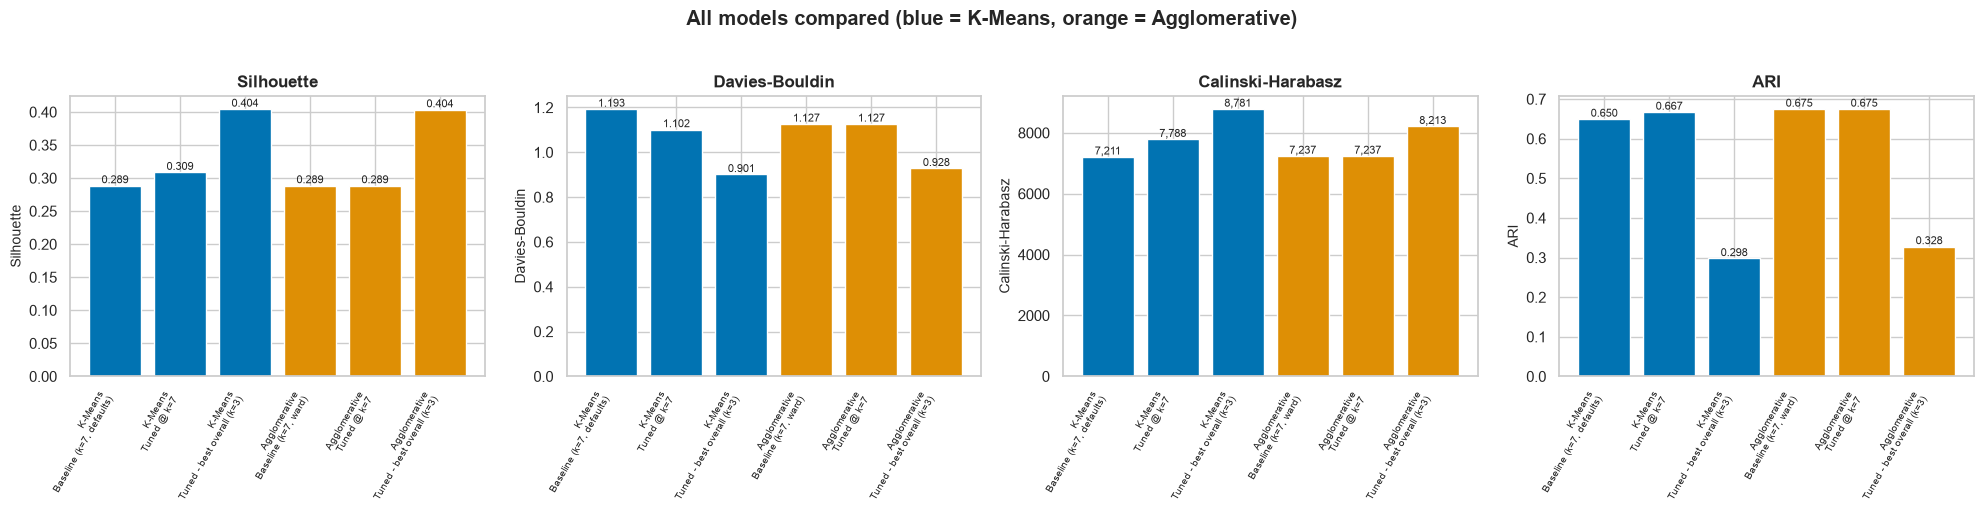

In [28]:
metrics_plot = ["Silhouette", "Davies-Bouldin", "Calinski-Harabasz", "ARI"]
labels_x = [f"{a}\n{v}" for a, v in results.index]
fig, axes = plt.subplots(1, 4, figsize=(20, 5))
for ax, m in zip(axes, metrics_plot):
    vals = results[m].astype(float).values
    ax.bar(range(len(vals)), vals, color=[PAL[0] if a == "K-Means" else PAL[1] for a, _ in results.index])
    for i, v in enumerate(vals): ax.text(i, v, f"{v:.3f}" if abs(v) < 100 else f"{v:,.0f}", ha="center", va="bottom", fontsize=8)
    ax.set_xticks(range(len(vals))); ax.set_xticklabels(labels_x, rotation=60, ha="right", fontsize=7); ax.set_title(m); ax.set_ylabel(m)
plt.suptitle("All models compared (blue = K-Means, orange = Agglomerative)", fontweight="bold", y=1.02)
plt.tight_layout(); plt.show()

## 10. Cluster Visualisation — PCA (mandatory) and t-SNE
Every model's labels are drawn on the **same 2-D PCA projection** (first two principal components of the reference space) next to the ground-truth varieties, so the panels are directly comparable (guideline requirement: PCA plot with cluster colouring for **every** algorithm). t-SNE is computed once on a subsample and re-used for every model.

PC1 explains 55.5% and PC2 26.4% of variance (total 81.9%)


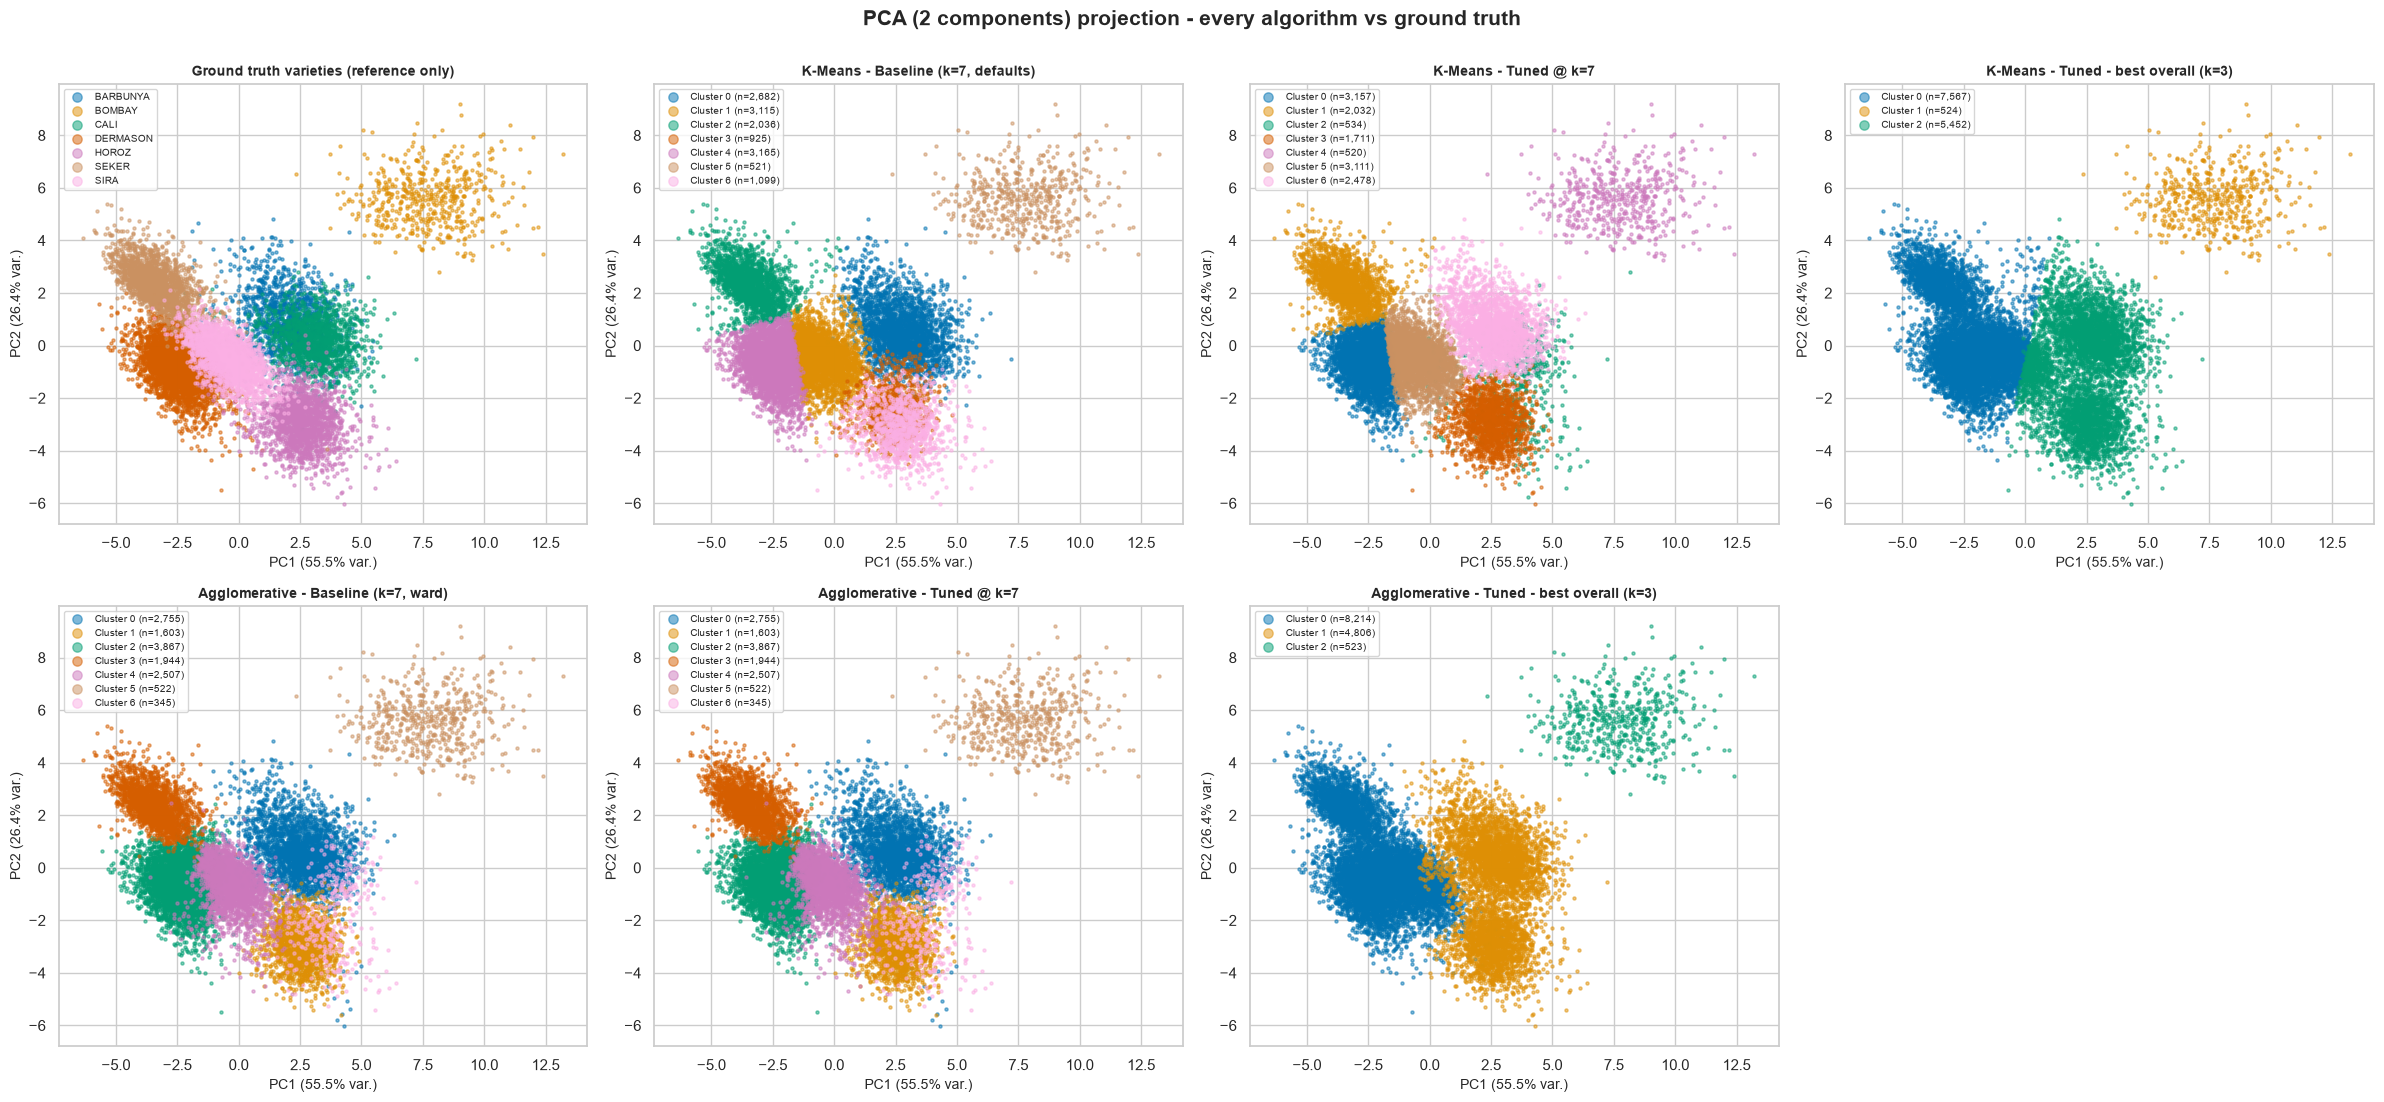

In [29]:
pca2 = PCA(n_components=2, random_state=RANDOM_STATE); P = pca2.fit_transform(REF)
ev = pca2.explained_variance_ratio_; print(f"PC1 explains {ev[0]*100:.1f}% and PC2 {ev[1]*100:.1f}% of variance (total {ev.sum()*100:.1f}%)")
classes = sorted(y_true.unique()); cmap_true = {c: PAL[i] for i, c in enumerate(classes)}

def panel(ax, emb, labels, title, true=False, xl="", yl="", s=5):
    if true:
        for c in classes:
            m = (labels == c); ax.scatter(emb[m, 0], emb[m, 1], s=s, alpha=.5, color=cmap_true[c], label=c)
    else:
        for c in np.unique(labels):
            m = labels == c; ax.scatter(emb[m, 0], emb[m, 1], s=s, alpha=.5, color=PAL[c % 10], label=f"Cluster {c} (n={m.sum():,})")
    ax.set_title(title, fontsize=10); ax.set_xlabel(xl); ax.set_ylabel(yl); ax.legend(markerscale=3, fontsize=7, loc="best")

def grid_plot(emb, idx, xl, yl, suptitle):
    fig, axes = plt.subplots(2, 4, figsize=(24, 11)); axes = axes.ravel()
    panel(axes[0], emb, y_true.values[idx], "Ground truth varieties (reference only)", True, xl, yl)
    for ax, ((algo, var), (lab, cfg)) in zip(axes[1:], models.items()):
        panel(ax, emb, lab[idx], f"{algo} - {var}", False, xl, yl)
    axes[7].axis("off"); plt.suptitle(suptitle, fontsize=15, fontweight="bold", y=1.0); plt.tight_layout(); plt.show()

ALL_IDX = np.arange(N)
grid_plot(P, ALL_IDX, f"PC1 ({ev[0]*100:.1f}% var.)", f"PC2 ({ev[1]*100:.1f}% var.)", "PCA (2 components) projection - every algorithm vs ground truth")

**Observation.** Compare each model's panel against the "ground truth" reference panel: the Bombay variety (usually the outlying blob in the ground-truth panel) shows up as its own dedicated cluster in almost every model, since it is the easiest group to find. The real test is whether a model's cluster boundaries within the dense central blob line up with the Dermason/Sira/Seker/Cali/Horoz/Barbunya boundaries in the reference panel, or whether it instead slices that blob up differently (e.g. along an axis PCA doesn't emphasise). Models with a higher ARI/NMI in Section 9 should visibly track the ground-truth colour regions more closely here. Note that PCA is a linear projection capturing only a fraction of the variance in two axes, so some overlap between clusters in 2-D is expected even for a good clustering in the full feature space.

t-SNE on 4000 beans took 7s


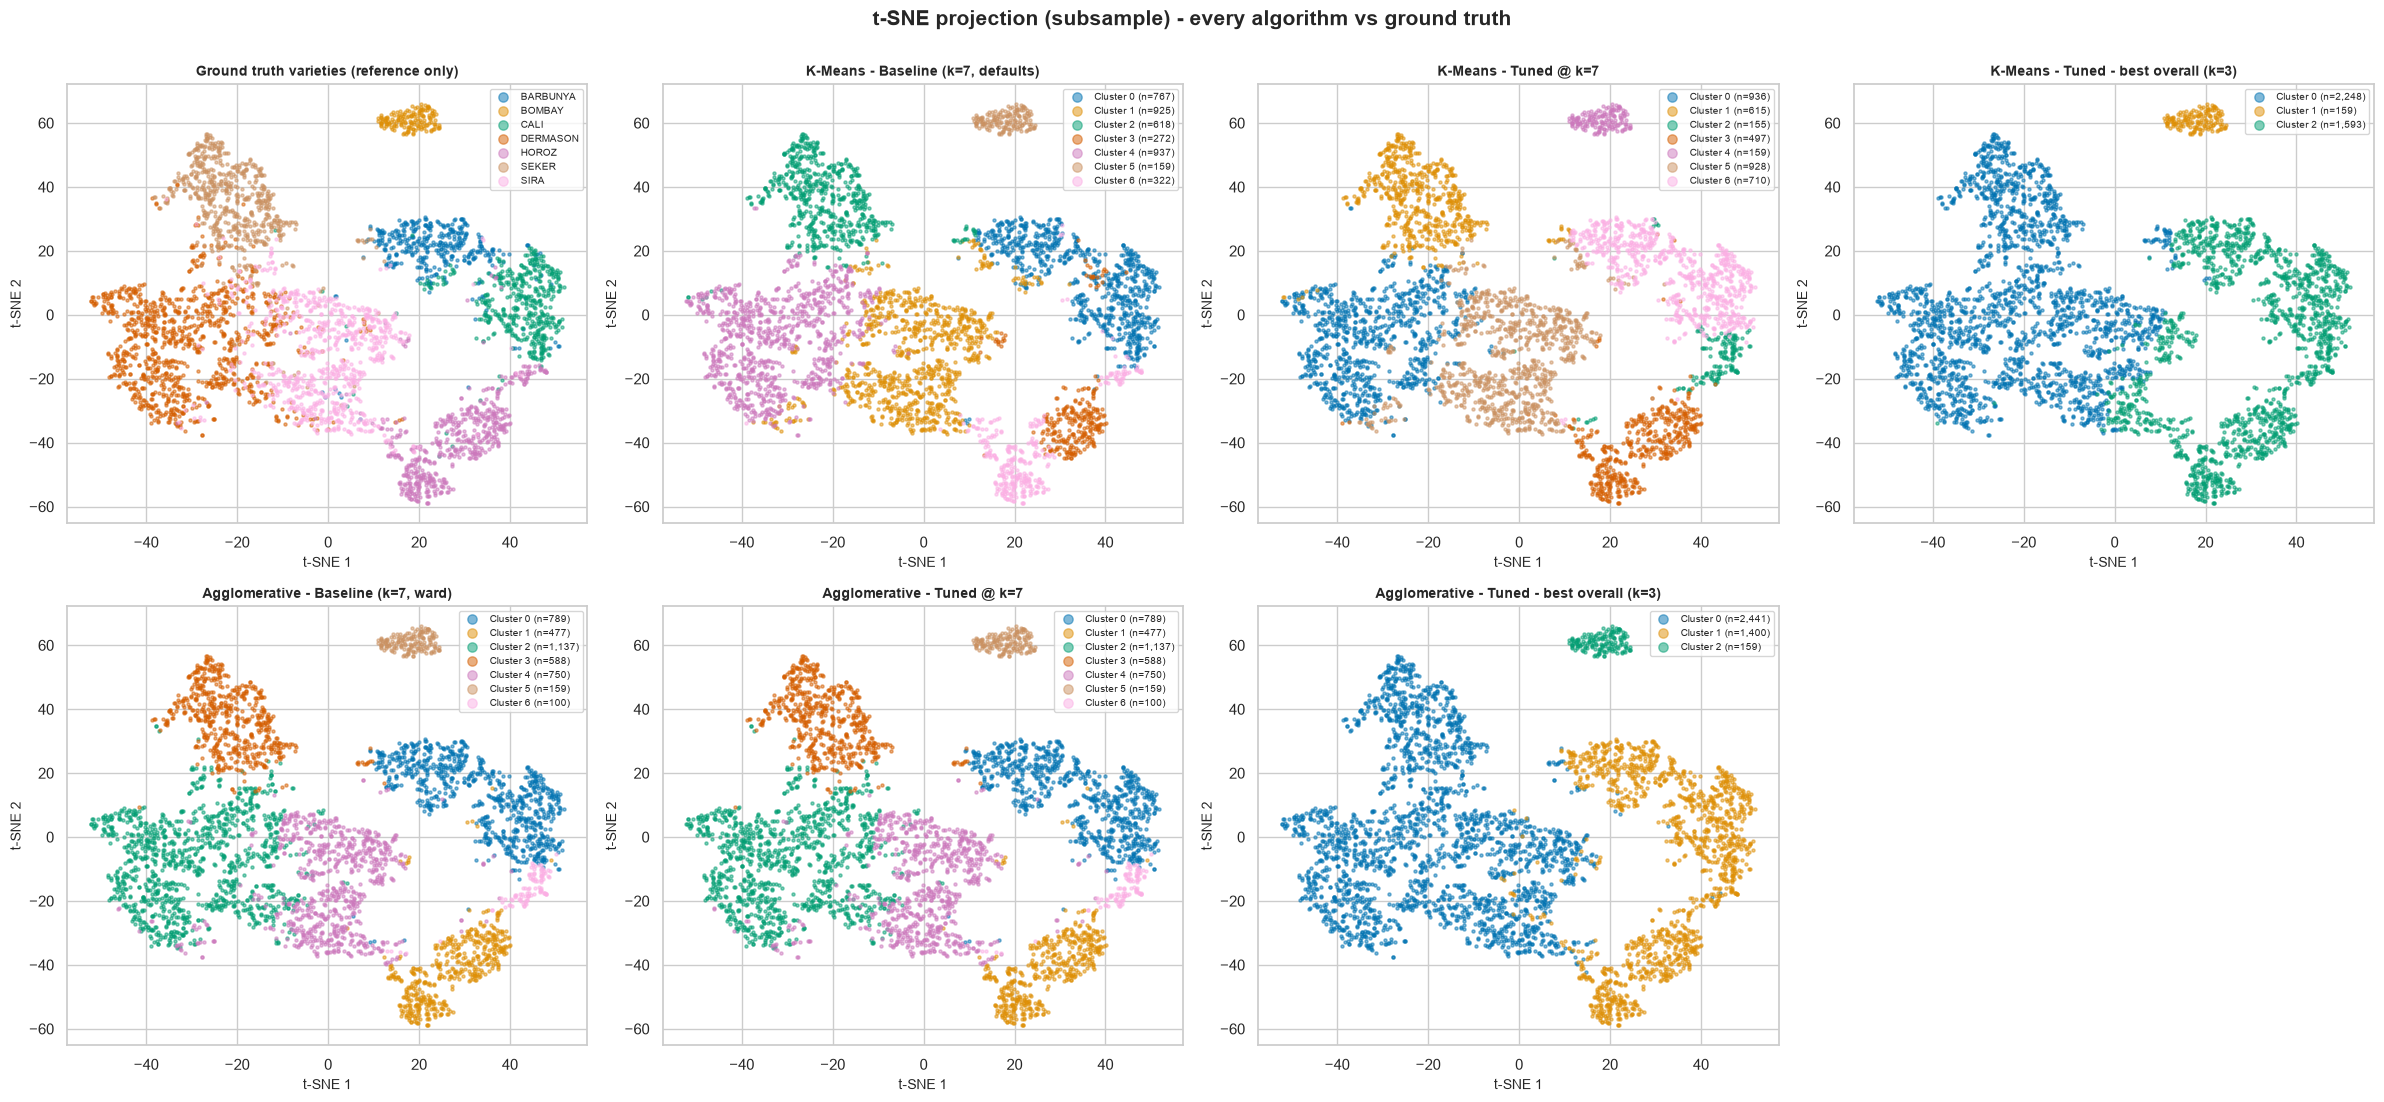

In [30]:
TSNE_N = 4000
TSNE_IDX = np.random.RandomState(RANDOM_STATE).choice(N, TSNE_N, replace=False)
t0 = time.time()
T = TSNE(n_components=2, perplexity=40, init="pca", learning_rate="auto", random_state=RANDOM_STATE).fit_transform(REF[TSNE_IDX])
print(f"t-SNE on {TSNE_N} beans took {time.time()-t0:.0f}s")
grid_plot(T, TSNE_IDX, "t-SNE 1", "t-SNE 2", "t-SNE projection (subsample) - every algorithm vs ground truth")

**Observation.** t-SNE typically separates the seven varieties into more visually distinct islands than linear PCA does (since it preserves local neighbourhoods rather than global variance), which makes it easier to see, by eye, exactly which pairs of varieties a given clustering solution merges or splits incorrectly. Because t-SNE coordinates are non-linear and non-metric, they are used here only for visual inspection, never for computing the Section 5 quality metrics.

## 11. Cluster Interpretation and Post-hoc Validation

### 11.1 What does each cluster look like? (feature profile of the final selected K-Means model)

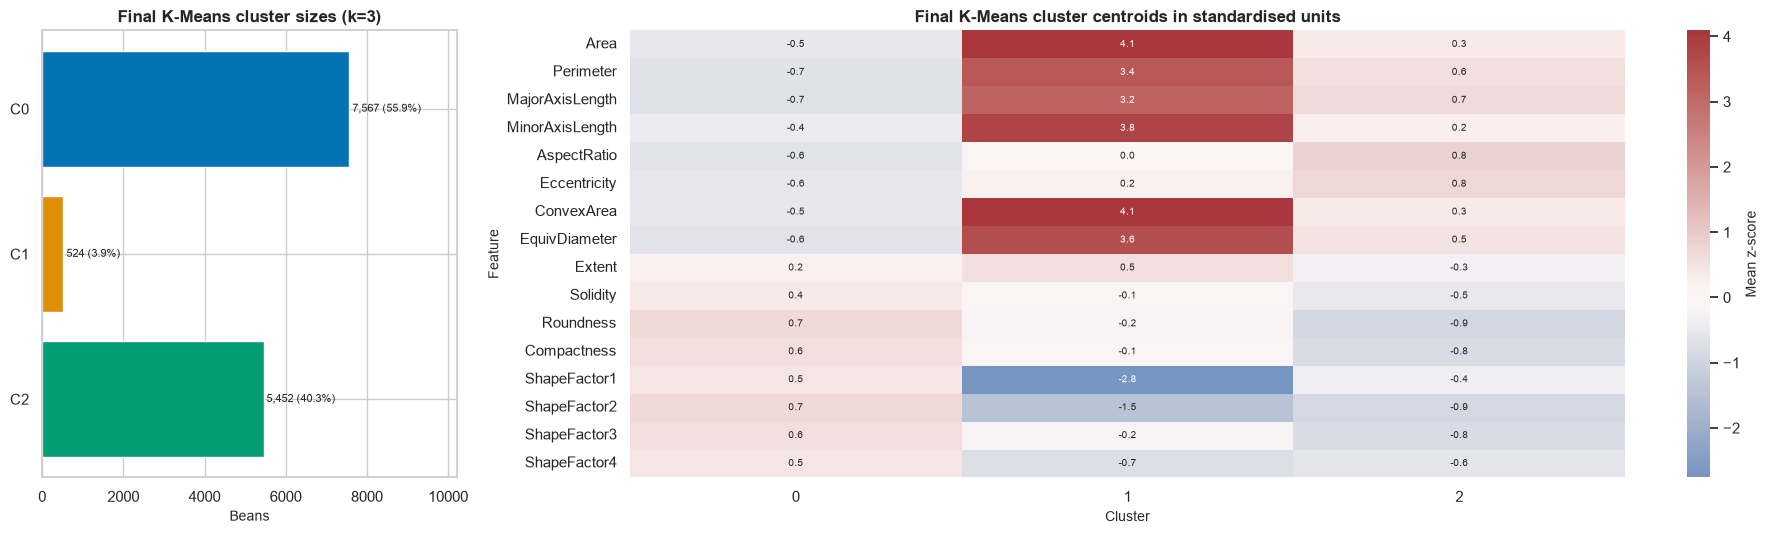

Final K-Means configuration:
k-means++, n_init=10, standard/all

Cluster means in original units (selected features):


,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRatio,Roundness,Solidity,ShapeFactor1
cluster,,,,,,,,
0,37407.089,714.418,259.943,182.588,1.432,0.914,0.989,0.007
1,173264.840,1584.640,592.701,374.123,1.585,0.864,0.987,0.003
2,63203.426,979.975,376.886,213.307,1.787,0.819,0.985,0.006


In [31]:
# Feature profile of the final selected K-Means model.
FINAL_K = int(km_best_all["k"])
FINAL_KM_KEY = (
    "K-Means",
    f"Tuned - best overall (k={FINAL_K})"
)

lab_final, final_cfg_description = models[
    FINAL_KM_KEY
]

prof_raw = (
    X.assign(cluster=lab_final)
    .groupby("cluster")
    .mean()
)

prof_z = (
    REF_DF.assign(cluster=lab_final)
    .groupby("cluster")
    .mean()
)

size = (
    pd.Series(lab_final)
    .value_counts()
    .sort_index()
)

fig, axes = plt.subplots(
    1,
    2,
    figsize=(19, 5.5),
    gridspec_kw={"width_ratios": [1, 3]}
)

axes[0].barh(
    [f"C{c}" for c in size.index],
    size.values,
    color=[
        PAL[c % 10]
        for c in size.index
    ]
)

for i, v in enumerate(size.values):
    axes[0].text(
        v,
        i,
        f" {v:,} ({v/N*100:.1f}%)",
        va="center",
        fontsize=8
    )

axes[0].set_title(
    f"Final K-Means cluster sizes (k={FINAL_K})"
)
axes[0].set_xlabel("Beans")
axes[0].invert_yaxis()
axes[0].set_xlim(
    0,
    size.max() * 1.35
)

sns.heatmap(
    prof_z.T,
    annot=True,
    fmt=".1f",
    cmap="vlag",
    center=0,
    cbar_kws={"label": "Mean z-score"},
    annot_kws={"size": 7},
    ax=axes[1]
)

axes[1].set_title(
    "Final K-Means cluster centroids "
    "in standardised units"
)
axes[1].set_xlabel("Cluster")
axes[1].set_ylabel("Feature")

plt.tight_layout()
plt.show()

print(
    "Final K-Means configuration:"
)
print(final_cfg_description)

print(
    "\nCluster means in original units "
    "(selected features):"
)

display(
    prof_raw[
        [
            "Area",
            "Perimeter",
            "MajorAxisLength",
            "MinorAxisLength",
            "AspectRatio",
            "Roundness",
            "Solidity",
            "ShapeFactor1"
        ]
    ]
    .round(3)
)

**Observation.** Read each column of the centroid heat-map as a "fingerprint" for that cluster: a column that is red (above-average) on `Area`/`Perimeter`/`MajorAxisLength` but blue on `AspectRatio` describes a large, round bean (matching Bombay); a column red on `AspectRatio` and blue on `Roundness` describes a long, thin bean (matching Horoz/Sira). Use this table together with the Section 11.2 cross-tabulation to assign an informal variety name to each numbered cluster.

### 11.2 How do clusters map onto the real varieties? (post-hoc only)

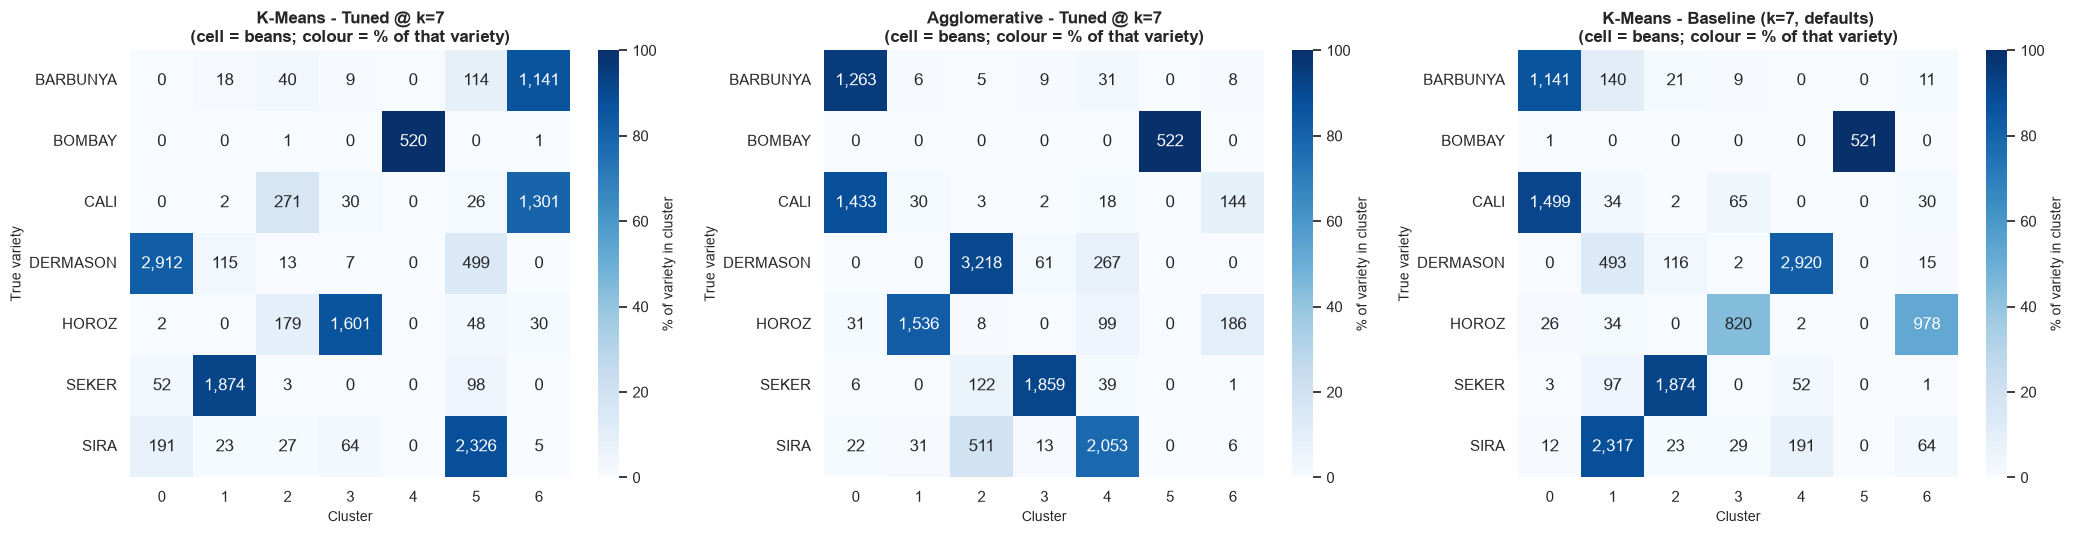

Cluster-by-cluster composition of the K-Means k=7 reference model:


,size,dominant variety,purity_%,2nd variety,2nd share_%
cluster,,,,,
0,3157,DERMASON,92.2,SIRA,6.1
1,2032,SEKER,92.2,DERMASON,5.7
2,534,CALI,50.7,HOROZ,33.5
3,1711,HOROZ,93.6,SIRA,3.7
4,520,BOMBAY,100.0,SIRA,0.0
5,3111,SIRA,74.8,DERMASON,16.0
6,2478,CALI,52.5,BARBUNYA,46.0



Share of each true variety that falls into its single best-matching cluster:


Class,BOMBAY,SEKER,SIRA,BARBUNYA,HOROZ,DERMASON,CALI
best-cluster recall %,99.6,92.5,88.2,86.3,86.1,82.1,79.8


In [32]:
# Post-hoc validation at the known seven-variety granularity.
# IMPORTANT: this section is interpretation/validation only.
# The Class labels were not used to fit or tune the models.

def crosstab_heatmap(
    lab,
    title,
    ax
):
    ct = pd.crosstab(
        y_true,
        pd.Series(
            lab,
            name="cluster"
        )
    )

    pct = (
        ct.div(
            ct.sum(axis=1),
            axis=0
        ) * 100
    )

    sns.heatmap(
        pct,
        annot=ct.values,
        fmt=",d",
        cmap="Blues",
        vmin=0,
        vmax=100,
        cbar_kws={
            "label": "% of variety in cluster"
        },
        ax=ax
    )

    ax.set_title(title)
    ax.set_xlabel("Cluster")
    ax.set_ylabel("True variety")


fig, axes = plt.subplots(
    1,
    3,
    figsize=(21, 5.5)
)

comparison_keys = [
    (
        "K-Means",
        "Tuned @ k=7"
    ),
    (
        "Agglomerative",
        "Tuned @ k=7"
    ),
    (
        "K-Means",
        "Baseline (k=7, defaults)"
    )
]

for ax, key in zip(
    axes,
    comparison_keys
):

    crosstab_heatmap(
        models[key][0],
        f"{key[0]} - {key[1]}\n"
        "(cell = beans; colour = % of that variety)",
        ax
    )

plt.tight_layout()
plt.show()

# Detailed post-hoc composition of the K-Means k=7 reference model.
lab_k7_reference = models[
    ("K-Means", "Tuned @ k=7")
][0]

ct_7 = pd.crosstab(
    pd.Series(
        lab_k7_reference,
        name="cluster"
    ),
    y_true
)

summary_7 = pd.DataFrame({
    "size": ct_7.sum(axis=1),
    "dominant variety": ct_7.idxmax(axis=1),
    "purity_%": (
        ct_7.max(axis=1)
        / ct_7.sum(axis=1)
        * 100
    ).round(1),
    "2nd variety": ct_7.apply(
        lambda r:
        r.sort_values().index[-2],
        axis=1
    ),
    "2nd share_%": (
        ct_7.apply(
            lambda r:
            r.sort_values().iloc[-2],
            axis=1
        )
        / ct_7.sum(axis=1)
        * 100
    ).round(1)
})

print(
    "Cluster-by-cluster composition "
    "of the K-Means k=7 reference model:"
)

display(
    summary_7
)

# Post-hoc recall of each known variety.
recall_7 = (
    ct_7.max(axis=0)
    / ct_7.sum(axis=0)
    * 100
).round(1).sort_values(
    ascending=False
)

print(
    "\nShare of each true variety that falls "
    "into its single best-matching cluster:"
)

display(
    recall_7.rename(
        "best-cluster recall %"
    ).to_frame().T
)

**Observation.** Bombay is concentrated in a single cluster column at close to 100%, confirming it as the "easy" variety, and the recall table above shows which other varieties (typically Seker, Barbunya and Horoz) are also recovered largely intact. The remaining rows show each cluster's beans coming predominantly from one or two adjacent varieties (e.g. Dermason/Sira bleed-through into the same clusters), which is exactly what would be expected given how much those varieties overlap in the Section 3.4 scatter plots — the clustering recovers *real* agronomic groupings, just not with perfect one-to-one purity, because the underlying shape features themselves only partially separate the six non-Bombay varieties.

## 12. Robustness and Generalisation Checks
A helper that turns any winning K-Means configuration into a complete scikit-learn `Pipeline` (feature selection → scaler → optional PCA → K-Means) is defined first, because it is reused for the hold-out check below and for the deployed artefact in Section 14.

In [33]:
def make_km_pipeline(
    cfg,
    seed=RANDOM_STATE
):
    """
    Complete preprocessing + K-Means pipeline.

    The pipeline accepts the original 16-column
    feature DataFrame and performs:
        feature selection
        scaling
        optional PCA
        K-Means
    """

    steps = []

    if cfg["fset"] == "decorr":
        steps.append(
            (
                "select",
                ColumnTransformer(
                    [
                        (
                            "keep",
                            "passthrough",
                            DECORR_COLS
                        )
                    ],
                    remainder="drop"
                )
            )
        )

    steps.append(
        (
            "scaler",
            SCALERS[cfg["scaler"]]()
        )
    )

    if cfg["fset"] == "pca95":
        steps.append(
            (
                "pca",
                PCA(
                    n_components=0.95,
                    random_state=RANDOM_STATE
                )
            )
        )

    steps.append(
        (
            "kmeans",
            KMeans(
                n_clusters=int(cfg["k"]),
                init=cfg["init"],
                n_init=int(cfg["n_init"]),
                random_state=seed
            )
        )
    )

    return Pipeline(steps)


# Sanity check:
# The pipeline should reproduce the selected K-Means partition.
chk = make_km_pipeline(
    km_best_all
).fit(X)

pipeline_labels = chk[
    "kmeans"
].labels_

ari_check = adjusted_rand_score(
    pipeline_labels,
    lab_km_ta
)

print(
    "Pipeline reproduction ARI "
    "(1.0 means identical partition):",
    round(ari_check, 4)
)

assert np.array_equal(
    pipeline_labels,
    lab_km_ta
), (
    "Pipeline labels do not exactly match "
    "the selected K-Means labels."
)

print(
    "Pipeline sanity check passed."
)

Pipeline reproduction ARI (1.0 means identical partition): 1.0
Pipeline sanity check passed.


### 12.1 Sensitivity to random initialisation

K-Means depends on the random seed. We fit the final selected K-Means configuration (`k = 3`) with 10 different seeds and measure (a) the spread of the internal scores and (b) how similar the resulting partitions are to each other using pairwise ARI. An ARI close to 1.0 indicates that the clustering partition is stable across random initialisations.

Agglomerative clustering is deterministic given its inputs, so it does not have this source of variability.

In [34]:
# Sensitivity to random initialisation
# for the final selected K-Means configuration.

FINAL_K = int(km_best_all["k"])

Zk = FEATS[
    (
        km_best_all["scaler"],
        km_best_all["fset"]
    )
]

seed_labs = []
seed_rows = []

for s in range(10):

    m = KMeans(
        n_clusters=FINAL_K,
        init=km_best_all["init"],
        n_init=int(km_best_all["n_init"]),
        random_state=s
    ).fit(Zk)

    seed_labs.append(
        m.labels_
    )

    seed_rows.append({
        "seed": s,
        "inertia": m.inertia_,
        **internal_metrics(
            REF,
            m.labels_,
            sil_sample=4000
        )
    })

seed_df = (
    pd.DataFrame(seed_rows)
    .set_index("seed")
)

pair = [
    adjusted_rand_score(a, b)
    for a, b in itertools.combinations(
        seed_labs,
        2
    )
]

display(
    seed_df
    .describe()
    .loc[
        ["mean", "std", "min", "max"]
    ]
    .round(4)
)

print(
    f"Final K-Means k = {FINAL_K}"
)

print(
    f"Pairwise ARI between seeds: "
    f"mean = {np.mean(pair):.3f}, "
    f"min = {np.min(pair):.3f}"
)

,inertia,silhouette,davies_bouldin,calinski_harabasz
mean,94331.7358,0.4039,0.9013,8781.2654
std,0.0073,0.0000,0.0000,0.0007
min,94331.7213,0.4038,0.9013,8781.2651
max,94331.7406,0.4039,0.9013,8781.2667


Final K-Means k = 3
Pairwise ARI between seeds: mean = 1.000, min = 0.999


**Observation.** The standard deviation of Silhouette/Davies-Bouldin/Calinski-Harabasz across seeds (table above) shows how much the result depends on the random start, and the pairwise ARI between seeds measures partition stability directly: values close to 1.0 mean the tuned solution is a stable, reproducible optimum rather than an artefact of one lucky random start; noticeably lower values would mean several distinct local optima exist and the choice of seed matters (which is why `random_state = 42` is fixed everywhere).

### 12.2 Hold-out generalisation (leakage-safe check)
Here the guideline's *fit on train only* rule is applied literally. Beans are split 80/20 at random. The complete tuned pipeline (scaler, optional PCA, K-Means) is fitted on the **training** beans only; the unseen **test** beans are passed through the training-fitted pipeline and assigned to the nearest training centroid. Quality metrics are computed in a standardised reference space whose scaler is also fitted on the training beans only. If the clusters reflect real structure (not an artefact of this particular sample), the test-set scores should be close to the training-set scores.

In [35]:
# Leakage-safe 80/20 hold-out check
# for the final selected K-Means configuration.

FINAL_K = int(km_best_all["k"])

Xtr, Xte, ytr, yte = train_test_split(
    X,
    y_true,
    test_size=0.2,
    random_state=RANDOM_STATE
)

# The complete preprocessing pipeline is fitted
# ONLY on the training data.
pipe_h = make_km_pipeline(
    km_best_all
).fit(Xtr)

ltr = pipe_h[
    "kmeans"
].labels_

lte = pipe_h.predict(
    Xte
)

# Train-fitted reference scaler for evaluation.
ref_h = StandardScaler().fit(Xtr)

Rtr = ref_h.transform(Xtr)
Rte = ref_h.transform(Xte)

hold = pd.DataFrame({
    "train (80%)": {
        **internal_metrics(
            Rtr,
            ltr,
            sil_sample=4000
        ),
        "ARI (post-hoc)": adjusted_rand_score(
            ytr,
            ltr
        ),
        "NMI (post-hoc)": normalized_mutual_info_score(
            ytr,
            ltr
        )
    },

    "test (20%)": {
        **internal_metrics(
            Rte,
            lte
        ),
        "ARI (post-hoc)": adjusted_rand_score(
            yte,
            lte
        ),
        "NMI (post-hoc)": normalized_mutual_info_score(
            yte,
            lte
        )
    }
})

hold["difference"] = (
    hold["test (20%)"]
    - hold["train (80%)"]
)

display(
    hold.round(4)
)

print(
    f"Final selected K-Means: k = {FINAL_K}"
)

print(
    "Test-set cluster sizes:",
    np.bincount(
        lte,
        minlength=FINAL_K
    )
)

,train (80%),test (20%),difference
silhouette,0.4070,0.4032,-0.0038
davies_bouldin,0.9002,0.8989,-0.0013
calinski_harabasz,6991.7333,1828.4178,-5163.3155
ARI (post-hoc),0.2990,0.2951,-0.0039
NMI (post-hoc),0.4878,0.4832,-0.0046


Final selected K-Means: k = 3
Test-set cluster sizes: [ 114 1078 1517]


**Observation.** The train and test Silhouette and Davies-Bouldin scores remain very close, while the post-hoc ARI and NMI values also change only slightly between the two partitions. This indicates that the three-cluster structure identified by the selected K-Means configuration is reasonably stable under this hold-out split.

The Calinski-Harabasz values are not directly compared by magnitude between the training and test partitions because the statistic depends on sample size.

Because the scaler and clustering pipeline were fitted on the training beans only in this experiment, this check follows the leakage-safe preprocessing requirement.

## 13. Final Model Selection

The six model/variant configurations are compared using two separate perspectives.

### 1. Internal clustering quality

The primary model-selection criteria are the three label-free clustering metrics:

- Silhouette Score — higher is better
- Davies-Bouldin Index — lower is better
- Calinski-Harabasz Index — higher is better

These metrics are appropriate for unsupervised model selection because they do not require the known bean variety labels.

### 2. Post-hoc external validation

After the clustering models have been fitted, the known `Class` labels are used only to interpret and validate the discovered clusters using:

- Adjusted Rand Index (ARI)
- Normalized Mutual Information (NMI)
- Purity
- Homogeneity
- Completeness
- V-measure

These external measures are **not used during model fitting or hyperparameter tuning**.

The `k = 7` configurations are additionally examined as a reference because the dataset contains seven registered bean varieties. This allows comparison with the known varieties during post-hoc validation. However, the final deployment configuration is selected using the label-free internal metrics across the tested configurations.

In [36]:
# Final model comparison.
#
# Internal metrics are used for model selection.
# External metrics are reported only for post-hoc validation.

summary_cols = INTERNAL + [
    "ARI",
    "NMI",
    "purity"
]

sel = (
    results[summary_cols]
    .astype(float)
    .copy()
)

# ---------------------------------------------------------
# 1. Label-free internal ranking
# ---------------------------------------------------------

sel["rank_internal (mean)"] = pd.concat(
    [
        sel["Silhouette"].rank(
            ascending=False
        ),
        sel["Davies-Bouldin"].rank(
            ascending=True
        ),
        sel["Calinski-Harabasz"].rank(
            ascending=False
        )
    ],
    axis=1
).mean(axis=1)

# ---------------------------------------------------------
# 2. External ranking — post-hoc reporting only
# ---------------------------------------------------------

sel["rank_external (mean)"] = pd.concat(
    [
        sel["ARI"].rank(
            ascending=False
        ),
        sel["NMI"].rank(
            ascending=False
        ),
        sel["purity"].rank(
            ascending=False
        )
    ],
    axis=1
).mean(axis=1)

print(
    "=== FINAL MODEL COMPARISON ==="
)

display(
    sel.sort_values(
        "rank_internal (mean)"
    ).round(4)
)

# Final selection is based ONLY on internal metrics.
best_internal = (
    sel["rank_internal (mean)"]
    .idxmin()
)

best_external_posthoc = (
    sel["rank_external (mean)"]
    .idxmin()
)

rho, _ = spearmanr(
    sel["rank_internal (mean)"],
    sel["rank_external (mean)"]
)

print(
    "\nSelected by label-free internal metrics:"
)

print(
    f"  {best_internal}"
)

print(
    "\nHighest post-hoc external agreement "
    "(reported only, NOT used for selection):"
)

print(
    f"  {best_external_posthoc}"
)

print(
    f"\nSpearman correlation between internal "
    f"and external rankings: {rho:.2f}"
)

# Separate k=7 reference comparison.
k7_variants = [
    idx
    for idx in sel.index
    if results.loc[idx, "k"] == 7
]

k7_only = sel.loc[k7_variants]

best_k7_internal = (
    k7_only[
        "rank_internal (mean)"
    ].idxmin()
)

best_k7_external = (
    k7_only[
        "rank_external (mean)"
    ].idxmin()
)

print(
    "\nBest k=7 configuration by internal metrics:"
)

print(
    best_k7_internal
)

print(
    "\nBest k=7 configuration by post-hoc validation:"
)

print(
    best_k7_external
)

print(
    "\nFinal deployment configuration:"
)

print(
    f"K-Means, k={int(km_best_all['k'])}, "
    f"{km_best_all['scaler']}/"
    f"{km_best_all['fset']}, "
    f"init={km_best_all['init']}, "
    f"n_init={int(km_best_all['n_init'])}"
)

=== FINAL MODEL COMPARISON ===


Silhouette  Davies-Bouldin  Calinski-Harabasz     ARI     NMI  purity  rank_internal (mean)  rank_external (mean)
Algorithm     Variant                                                                                                                                      
K-Means       Tuned - best overall (k=3)      0.4044          0.9013          8781.2651  0.2976  0.4856  0.4335                1.0000                5.6667
Agglomerative Tuned - best overall (k=3)      0.4036          0.9284          8212.8678  0.3278  0.5396  0.4325                2.0000                5.3333
K-Means       Tuned @ k=7                     0.3088          1.1016          7787.8566  0.6674  0.7126  0.7978                3.0000                3.3333
Agglomerative Baseline (k=7, ward)            0.2886          1.1266          7237.0082  0.6749  0.7306  0.7980                4.8333                1.8333
              Tuned @ k=7                     0.2886          1.1266          7237.0082  0.6749  0.7306  0.7980                4.8333                1.8333
K-Means       Baseline (k=7, defaults)        0.2886          1.1930          7210.5888  0.6496  0.7100  0.8070                5.3333                3.0000


Selected by label-free internal metrics:
  ('K-Means', 'Tuned - best overall (k=3)')

Highest post-hoc external agreement (reported only, NOT used for selection):
  ('Agglomerative', 'Baseline (k=7, ward)')

Spearman correlation between internal and external rankings: -0.82

Best k=7 configuration by internal metrics:
('K-Means', 'Tuned @ k=7')

Best k=7 configuration by post-hoc validation:
('Agglomerative', 'Baseline (k=7, ward)')

Final deployment configuration:
K-Means, k=3, standard/all, init=k-means++, n_init=10


### Final model selection

The final clustering configuration is selected using the **label-free internal clustering metrics** only.

The three mandatory internal metrics are:

- **Silhouette Score:** higher is better
- **Davies-Bouldin Index:** lower is better
- **Calinski-Harabasz Index:** higher is better

The Section 8 tuning stage ranks configurations using these three metrics and the minimum cluster-size validity constraint.

For this dataset, the best overall K-Means configuration is the `k = 3` configuration identified by the internal-metric ranking.

The known `Class` labels are **not used to select this model**. They are used only after fitting for post-hoc validation through ARI, NMI, purity, homogeneity, completeness and V-measure.

The `k = 7` configurations are retained as a separate reference because the dataset contains seven known bean varieties. This allows the discovered clusters to be compared with the known varieties without allowing those labels to influence clustering or hyperparameter selection.

Therefore:

> **Final unsupervised model: K-Means, best internally ranked configuration, k = 3.**

The k=7 results remain available as a post-hoc analysis of how the clustering behaves at the known variety granularity.

## 14. Saving Artefacts & Conclusions

The selected K-Means configuration (`k = 3`) is saved as a scikit-learn `Pipeline`.

The pipeline contains the feature-selection/scaling steps required by the selected configuration followed by K-Means. It is fitted on the complete available feature dataset so that the final deployment artefact uses all available observations.

The saved pipeline can subsequently be loaded by a Streamlit/Gradio application and used to assign a new bean's 16 measurements to one of the three learned clusters using `pipeline.predict(...)`.

The `Class` column is not part of the pipeline and is never required for prediction.

The `cluster_names.json` file contains post-hoc descriptive mappings based on the dominant known variety in each cluster. These names are for interpretation/display only and were not used when fitting the clustering model.

The separate `k = 7` analysis is retained as a reference for comparing the unsupervised clustering structure with the seven known bean varieties.

In [37]:
# Final deployment artefact:
# selected using ONLY label-free internal clustering metrics.

best = km_best_all

FINAL_K = int(best["k"])

print(
    "Final deployment configuration:"
)

print(
    f"K-Means | k={FINAL_K} | "
    f"scaler={best['scaler']} | "
    f"features={best['fset']} | "
    f"init={best['init']} | "
    f"n_init={int(best['n_init'])}"
)

# Fit the complete pipeline on all available unlabeled observations.
final_pipe = make_km_pipeline(
    best
).fit(X)

# IMPORTANT:
# Obtain the cluster IDs directly from the SAVED PIPELINE.
# These are the exact IDs that a future application will produce.
final_labels = final_pipe.predict(X)

assert np.array_equal(
    final_labels,
    final_pipe["kmeans"].labels_
)

# ---------------------------------------------------------
# Post-hoc descriptive cluster -> dominant variety mapping
# ---------------------------------------------------------
#
# This mapping is NOT part of model fitting.
# It is only for interpretation/display.

final_ct = pd.crosstab(
    pd.Series(
        final_labels,
        name="cluster"
    ),
    y_true
)

cluster_names = {
    int(cluster): str(
        final_ct.loc[
            cluster
        ].idxmax()
    )
    for cluster in final_ct.index
}

cluster_purity = {
    int(cluster): float(
        final_ct.loc[cluster].max()
        / final_ct.loc[cluster].sum()
    )
    for cluster in final_ct.index
}

print(
    "\nPost-hoc cluster descriptions:"
)

display(
    pd.DataFrame({
        "cluster": list(cluster_names.keys()),
        "dominant_variety": list(
            cluster_names.values()
        ),
        "posthoc_purity": [
            cluster_purity[c]
            for c in cluster_names.keys()
        ]
    }).round(4)
)

# ---------------------------------------------------------
# Save artefacts
# ---------------------------------------------------------

joblib.dump(
    final_pipe,
    MODELS_DIR /
    "kmeans_final_pipeline.pkl"
)

with open(
    MODELS_DIR /
    "cluster_names.json",
    "w"
) as f:

    json.dump(
        {
            "cluster_to_variety": cluster_names,
            "posthoc_purity": cluster_purity,
            "feature_columns": feature_cols,
            "k": FINAL_K,
            "selection_method": (
                "label-free internal clustering metrics"
            )
        },
        f,
        indent=2
    )

results.reset_index().to_csv(
    MODELS_DIR /
    "clustering_results_table.csv",
    index=False
)

km_grid.to_csv(
    MODELS_DIR /
    "kmeans_tuning_grid.csv",
    index=False
)

agg_grid.to_csv(
    MODELS_DIR /
    "agglomerative_tuning_grid.csv",
    index=False
)

# ---------------------------------------------------------
# Reload and verify the saved artefact
# ---------------------------------------------------------

reloaded = joblib.load(
    MODELS_DIR /
    "kmeans_final_pipeline.pkl"
)

demo = reloaded.predict(
    X.iloc[:5]
)

assert np.array_equal(
    demo,
    final_labels[:5]
)

demo_names = [
    cluster_names.get(
        int(c),
        "Unknown"
    )
    for c in demo
]

print(
    "\nSaved to:",
    MODELS_DIR
)

print(
    "Reload test - first 5 beans "
    "assigned to clusters:",
    demo.tolist()
)

print(
    "Post-hoc descriptive names:",
    demo_names
)

print(
    "True varieties shown ONLY "
    "for post-hoc verification:",
    y_true.iloc[:5].tolist()
)

print(
    "\nSaved pipeline verification PASSED."
)

Final deployment configuration:
K-Means | k=3 | scaler=standard | features=all | init=k-means++ | n_init=10

Post-hoc cluster descriptions:


,cluster,dominant_variety,posthoc_purity
0,0,DERMASON,0.4633
1,1,BOMBAY,0.9962
2,2,HOROZ,0.3380



Saved to: models
Reload test - first 5 beans assigned to clusters: [0, 0, 0, 0, 0]
Post-hoc descriptive names: ['DERMASON', 'DERMASON', 'DERMASON', 'DERMASON', 'DERMASON']
True varieties shown ONLY for post-hoc verification: ['SEKER', 'SEKER', 'SEKER', 'SEKER', 'SEKER']

Saved pipeline verification PASSED.


### 14.1 Conclusions (generated from the results above)
The cell below prints the headline findings using the actual numbers computed in this run, so the write-up can never drift out of sync with the results.

In [38]:
# Final headline findings.
# All model-selection statements are based on label-free
# internal metrics. External metrics are explicitly post-hoc.

FINAL_K = int(km_best_all["k"])

# Post-hoc variety composition of the FINAL model.
final_ct = pd.crosstab(
    pd.Series(
        final_labels,
        name="cluster"
    ),
    y_true
)

final_summary = pd.DataFrame({
    "size": final_ct.sum(axis=1),
    "dominant variety": final_ct.idxmax(axis=1),
    "purity_%": (
        final_ct.max(axis=1)
        / final_ct.sum(axis=1)
        * 100
    ).round(1)
})

dominant_counts = (
    final_summary[
        "dominant variety"
    ]
    .value_counts()
)

merged = [
    f"{v} (split across {int(n)} clusters)"
    for v, n in dominant_counts.items()
    if n > 1
]

missing = sorted(
    set(y_true.unique())
    - set(
        final_summary[
            "dominant variety"
        ]
    )
)

print(
    "KEY FINDINGS"
)

print(
    "-" * 100
)

print(
    f"1. Elbow analysis selected a knee near "
    f"k = {K_KNEE}."
)

print(
    f"2. The individual internal metrics preferred "
    f"Silhouette k = {k_sil}, "
    f"Davies-Bouldin k = {k_db}, "
    f"and Calinski-Harabasz k = {k_ch}."
)

print(
    f"3. The complete K-Means tuning grid selected "
    f"k = {FINAL_K} as the best overall K-Means "
    f"configuration using only label-free internal metrics."
)

print(
    f"4. Final K-Means configuration: "
    f"{best['scaler']}/{best['fset']}, "
    f"init={best['init']}, "
    f"n_init={int(best['n_init'])}."
)

print(
    f"5. Final model internal metrics: "
    f"Silhouette = "
    f"{results.loc[('K-Means', f'Tuned - best overall (k={FINAL_K})'), 'Silhouette']:.4f}, "
    f"Davies-Bouldin = "
    f"{results.loc[('K-Means', f'Tuned - best overall (k={FINAL_K})'), 'Davies-Bouldin']:.4f}, "
    f"Calinski-Harabasz = "
    f"{results.loc[('K-Means', f'Tuned - best overall (k={FINAL_K})'), 'Calinski-Harabasz']:.2f}."
)

print(
    f"6. K-Means seed stability: "
    f"mean pairwise ARI = {np.mean(pair):.3f}, "
    f"minimum pairwise ARI = {np.min(pair):.3f}."
)

print(
    f"7. Hold-out check: test silhouette = "
    f"{hold.loc['silhouette', 'test (20%)']:.3f} "
    f"vs train = "
    f"{hold.loc['silhouette', 'train (80%)']:.3f}."
)

print(
    f"8. Post-hoc validation of the final model: "
    f"ARI = "
    f"{results.loc[('K-Means', f'Tuned - best overall (k={FINAL_K})'), 'ARI']:.4f}, "
    f"NMI = "
    f"{results.loc[('K-Means', f'Tuned - best overall (k={FINAL_K})'), 'NMI']:.4f}, "
    f"purity = "
    f"{results.loc[('K-Means', f'Tuned - best overall (k={FINAL_K})'), 'purity']:.4f}."
)

print(
    f"9. Final model dominant variety per cluster: "
    f"{final_summary['dominant variety'].tolist()}."
)

if missing:
    print(
        f"10. Varieties that do not dominate any final cluster: "
        f"{missing}."
    )
else:
    print(
        "10. Every known variety is the dominant variety "
        "of at least one final cluster."
    )

if merged:
    print(
        "11. Varieties represented as the dominant variety "
        f"of multiple clusters: {merged}."
    )

print(
    "\nThe known Class labels were used only for "
    "post-hoc validation and interpretation."
)

KEY FINDINGS
----------------------------------------------------------------------------------------------------
1. Elbow analysis selected a knee near k = 4.
2. The individual internal metrics preferred Silhouette k = 3, Davies-Bouldin k = 3, and Calinski-Harabasz k = 2.
3. The complete K-Means tuning grid selected k = 3 as the best overall K-Means configuration using only label-free internal metrics.
4. Final K-Means configuration: standard/all, init=k-means++, n_init=10.
5. Final model internal metrics: Silhouette = 0.4044, Davies-Bouldin = 0.9013, Calinski-Harabasz = 8781.27.
6. K-Means seed stability: mean pairwise ARI = 1.000, minimum pairwise ARI = 0.999.
7. Hold-out check: test silhouette = 0.403 vs train = 0.407.
8. Post-hoc validation of the final model: ARI = 0.2976, NMI = 0.4856, purity = 0.4335.
9. Final model dominant variety per cluster: ['DERMASON', 'BOMBAY', 'HOROZ'].
10. Varieties that do not dominate any final cluster: ['BARBUNYA', 'CALI', 'SEKER', 'SIRA'].

The kno

### 14.2 Interpretation, limitations and future work

**Interpretation.** The final K-Means configuration was selected using only label-free internal clustering metrics. The known bean varieties are used separately for post-hoc interpretation through ARI, NMI, purity, homogeneity, completeness and V-measure. The seven-cluster analysis is retained as a reference because the dataset contains seven known varieties, but the known class count is not used to select the final unsupervised model.

**Limitations.**

- Unsupervised clusters do not necessarily correspond one-to-one with human-defined bean varieties. The external validation metrics are therefore descriptive post-hoc measures rather than optimisation objectives.
- The Agglomerative tuning grid and dendrograms use a 2,500-bean subsample for computational tractability.
- The primary unsupervised analysis is fitted on the complete unlabeled dataset. A separate 80/20 hold-out experiment fits preprocessing only on the training partition to verify the selected K-Means pipeline under a leakage-safe protocol.
- The available 16 geometric features contain substantial overlap among several bean varieties, limiting how closely unsupervised geometric clusters can reproduce the seven human-defined categories.
- Only K-Means and Agglomerative clustering are required by the course guidelines. DBSCAN and Gaussian Mixture Models could be investigated as future extensions.

**Future work.** Additional shape ratios, image-derived texture/boundary features, density-based clustering and probabilistic clustering could be investigated to determine whether the boundaries between visually similar bean varieties can be represented more accurately.

The saved pipeline (`models/kmeans_final_pipeline.pkl`) can be used as the basis for a Streamlit/Gradio interface. The `cluster_names.json` mappings are post-hoc descriptive labels only and are not part of the clustering model.